# California Sierra Nevada rapid snowmelt/sublimation events (water years 1990-2026)

Companion to `CA_z500_t700_blocking_events_detrend_5day.ipynb`. That notebook finds
persistent California 500 hPa ridging and 700 hPa warm-spell events in ERA5
(Jan-Apr, 1990-2025 fit, 2026 scored out-of-sample). This notebook asks the other half
of the AR/snowpack project's question: *do those "heat waves" show up as unusually
rapid snowpack loss on the ground, and does snow lost late in the season recover?*

**Why SNOTEL (+ MSNT + CDEC) instead of an ERA5 snow variable.** The ERA5 archive used
for Z500/T700 also has snow depth water-equivalent (`SD`), snowmelt (`SMLT`), and snow
evaporation/sublimation (`ES`) over the same CA box. We did not use them here.
Lundquist et al. (2026, *Water Resources Research*, "Snow what? Comparing snow
products to reveal what works, where, and why") benchmark global reanalyses against
airborne-lidar SWE and find ERA5-Land (9 km resolution) already has a **-17.5%
basin-scale bias** and poor spatial fidelity in mountain terrain from coarse
resolution, recommending **9 km or finer**; SNODAS and the University of Arizona SWE
product do better (7.8-10.2% bias) and the Western US SWE Reanalysis (WUS-SR, the
"UCLA product") best of all (1.6% bias). The only ERA5 resolution in our archive is
plain 0.25 deg (~28 km) -- coarser than the ERA5-Land already judged inadequate for
Sierra Nevada terrain. Z500/T700 are large-scale free-tropospheric fields, not
resolution-sensitive the way surface snowpack is, so the companion notebook's ERA5
results stand; a gridded ERA5 snow budget would not. See Section 7 for how UA SWE /
SNODAS / WUS-SR could extend this analysis once credentialed access is set up.

**Station network (updated from the original SNOTEL-only pass).** NRCS SNOTEL
(`SNTL`) has no footprint south of ~38.1N in this region -- confirmed against the full
NRCS registry including inactive stations -- so a SNOTEL-only network misses the
Yosemite/Mammoth/Kings Canyon/Sequoia/Kern terrain entirely. Two sources fill that gap:
NRCS's own `MSNT` ("Cooperator Snow Sensors") network, served through the same AWDB
pipeline and QC/QA flagging as SNOTEL, and the California Data Exchange Center (CDEC),
which aggregates DWR, USBR, national-park, utility, and ranger-district sensors (raw
telemetry, QC'd here with heuristic physical-range checks). A station-ID/lat-lon
crosswalk found all 67 in-box MSNT stations already present in the CDEC pull under the
same or a near-identical ID -- so for those stations we keep the better-provenance
MSNT/AWDB version and drop CDEC's raw duplicate; the remaining CDEC-only stations (no
NRCS counterpart) are the only source for that coverage and are kept from the QC'd
CDEC feed. See `build_combined_sierra_swe.py` for the merge logic.

**Data used:**
- `combined_sierra_stations.csv`, `combined_sierra_swe_wy1990-2026.csv` -- 312 stations
  in the Sierra box (36 SNTL, 67 MSNT, 209 CDEC-only), water years 1990-2026, built by
  `build_combined_sierra_swe.py` from `get_snotel_box.py` / `get_msnt_box.py` /
  `get_cdec_box.py` + `qc_cdec_swe.py`. Of those 312, only **147 report at daily
  resolution** (36 SNTL + 67 MSNT + 44 CDEC-D) and feed the event-detection pipeline
  below; the other 165 are CDEC manual snow-course ("M"-only) sites with no automated
  sensor, too infrequent for a 5-day backward-difference decline metric, so they are
  metadata-only here (see Section 1's printed breakdown).
- `ca_z500_t700_events_1990-2025_detrended_mindur5.csv` -- the companion notebook's
  detrended, >=5-day, >=1 SD Z500 ridging / T700 warm-event table, used here as the
  "heat wave" record to compare against.

**Methodology, in brief** (details in each section):
- Restrict to stations inside a Sierra Nevada box (34.5-40N, 121-116.5W), chosen to
  capture the physical Sierra snow network (especially MSNT/CDEC coverage of the
  southern and eastern-crest terrain) -- the Section 5c precipitation check (dry/wet
  rain-on-snow classification) uses this same box; the companion's narrower box
  is still what's used for the dry/wet precipitation check in Section 5c, since that's
  an ERA5 atmospheric field, not a station footprint.
- Keep only daily (`D`) SWE records -- CDEC's manual monthly snow-course (`M`)
  readings are too infrequent for a 5-day backward-difference decline metric (147 of
  312 in-box stations qualify; see above).
- For each station, compute **min(SWE over a 3-day window) - SWE at the window's
  start** (mm/3day) -- not a plain endpoint difference -- only on days with >=25 mm
  (~1 in) of snowpack at the start of the window (SWE is a bounded, strongly seasonal
  state variable). This min-in-window metric was adopted in place of an earlier plain
  5-day backward difference (`swe[t]-swe[t-5]`), which is blind to the path between its
  two endpoints and misses melt-then-recovery episodes -- see Section 2 and the
  stress-test sections in Section 5 for the full comparison and why WINDOW=3 (not 5) is
  the better-performing choice for this metric specifically. Like the companion
  notebook, we build a **calendar-day climatology** of this decline metric (mean, std,
  pooled +/-5 calendar days across water years) and standardize: a January decline that
  would be unremarkable in May can still register as a large standardized anomaly in
  January, because "normal" for January is close to zero.
- **Detrending and held-out 2026**: the climatology and standard deviation are fit on
  water years 1990-2025 only; a single pooled linear year-trend (small and not
  significant, like T700's in the companion notebook) is removed for consistency.
  Water year 2026 (Oct 2025 - Jul 2026, spanning the March 2026 western US heat wave)
  is scored against this frozen baseline in Section 7, exactly mirroring the companion
  notebook's Section 8.
- **Event = gap-tolerant run of days where a sustained fraction of reporting Sierra
  stations are simultaneously in rapid decline** (>=1 SD below their own calendar-day
  normal), >=5 days, tolerating 1 sub-threshold gap day -- the same `find_events()`
  algorithm as the companion notebook, applied to a network-fraction series instead of
  a single box-averaged field.
- **Dry ablation vs. wet rain-on-snow (Section 5c)**: a sustained SWE drop isn't always
  heat-wave-driven melt/sublimation -- it can also be rain falling on existing
  snowpack during an active (often AR-driven) storm, a different mechanism entirely.
  Each event is checked against the companion notebook's own Sierra-sub-box
  precipitation record and flagged dry/wet accordingly.
- **Season vs. mechanism in the recovery analysis (Section 6b)**: whether a
  rapid-decline event overlaps a T700 warm event or not, events in the same part of
  the season recover at similar rates -- so the recovery-by-month pattern is checked
  against, and should be read as, a statement about seasonal timing rather than proof
  that heat-wave-triggered melt specifically is less recoverable.
- **Elevation representativeness**: the station network spans a wide elevation range,
  and "30% of reporting stations" is not automatically a basin-wide signal -- each
  event's contributing-station elevation range is checked against the network as a
  whole.
- **Parameter sensitivity**: `MIN_SWE_MM` (the snowpack floor required before a decline
  counts) is a round-number engineering choice in the instrument's native unit, not a
  value fit to the data -- re-running the pipeline at half (12.7mm) and double (50.8mm)
  that value, right after the elevation-representativeness check above, confirms the
  event counts, the 2026 record event, and the elevation-skew pattern are not artifacts
  of the specific 25mm chosen.
- **Significance testing**: headline percentages (match rates, enrichment, dry-vs-wet
  and matched-vs-unmatched comparisons) are accompanied by event-resampled bootstrap
  CIs, block-level Mann-Whitney tests, and Fisher's exact tests, rather than quoted as
  bare point estimates -- days within one event are autocorrelated, so testing at the
  day level would overstate confidence.

Ming Ge Oct 2026

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from pathlib import Path
from scipy.stats import linregress
import sys

# Pin PROJ_DATA before any geospatial package can be lazily imported. xarray's
# open_dataset/open_mfdataset builds its full backend registry on first call even
# when engine= is given explicitly, which imports every xarray-backend entry point
# installed in this broad environment -- including metpy -> cartopy -> fiona. GDAL's
# bundled PROJ context (separate from pyproj's own, already-correct one) doesn't
# reliably find its own proj.db unless PROJ_DATA is set before that first import, and
# prints a one-time, harmless 'ERROR 1: PROJ: proj_create_from_database...' straight
# to stderr if it isn't. Not needed for anything this notebook does (no map
# projections here) -- this just keeps that import quiet.
import os
os.environ.setdefault('PROJ_DATA', str(Path(sys.prefix) / 'share' / 'proj'))

sys.path.insert(0, str(Path.cwd()))
import ca_blocking_lib as lib

DATA_DIR = Path('/glade/campaign/mmm/c3we/mingge/ERA5/CA_blocking')

CLIM_WINDOW = 5          # +/- calendar days pooled for the climatology (matches companion notebook)
MIN_DURATION = 5         # minimum consecutive days for an event
MAX_GAP = 1              # max sub-threshold calendar days tolerated within an event
MIN_SWE_MM = 25.0        # ~1 in -- require this much SWE at window start before counting a decline
WINDOW = 3               # days spanned by the decline metric (see Section 2 -- ADOPTED from the
                         # metric x WINDOW tradeoff stress-test later in this notebook; was 5
                         # under the original endpoint-diff metric, now superseded)
SIGMA_THRESHOLDS = [1.0, 1.5, 2.0]   # station-day standardized-decline thresholds
NETWORK_THRESH = 0.3     # fraction of reporting Sierra stations in rapid decline -> network event day
YEARS = list(range(1990, 2026))      # fit years -- 2026 held out, scored separately (Section 7)
YEAR_2026 = 2026

# Matches the full SNOTEL+MSNT+CDEC station-fetch box, which was deliberately
# extended south/east to capture Yosemite/Mammoth/Kings Canyon/Sequoia/Kern terrain
# that SNOTEL alone never covered. Also reused as-is for Section 5c's precipitation
# sub-box (PRECIP_LON_W/E below), so the station network and the precip check now
# share exactly the same domain.
SIERRA_LAT_S, SIERRA_LAT_N = 34.5, 40.0
SIERRA_LON_W, SIERRA_LON_E = -121.0, -116.5

# Analysis season restricted to Jan 1 - May 31:
# keeps the record aligned with the companion notebook's Jan-Apr window (plus
# one extra month) and with precip_sf_ca_<year>.nc's Jan-May coverage (Section 5c),
MONTH_NAMES = {1: 'Jan', 2: 'Feb', 3: 'Mar', 4: 'Apr', 5: 'May'}

## 1. Load combined SNOTEL+MSNT+CDEC stations and daily SWE, restrict to the Sierra box

Loads the station metadata daily SWE built by `build_combined_sierra_swe.py`, restricts to 
the Sierra box, keeps only daily (`D`) records (147 of 312 in-box stations qualify ), and
reshapes to a date x station wide matrix spanning the full calendar. Event detection
itself is restricted to Jan 1 - May 31 in Section 3 -- not here -- so that Section 2's 
min-in-window decline metric (WINDOW=3 days) still has real December data to compute 
January's valuesfrom.

In [2]:
stations_csv = DATA_DIR / 'combined_sierra_stations.csv'
swe_csv = DATA_DIR / 'combined_sierra_swe_wy1990-2026.csv'
if not stations_csv.exists() or not swe_csv.exists():
    raise FileNotFoundError(
        f'{stations_csv.name} / {swe_csv.name} missing from {DATA_DIR}.\n'
        'Run get_snotel_box.py, get_msnt_box.py, get_cdec_box.py, qc_cdec_swe.py, '
        'check_msnt_cdec_overlap.py, then build_combined_sierra_swe.py first.'
    )

stations = pd.read_csv(stations_csv).rename(columns={'station_id': 'stationTriplet'})
swe_long = pd.read_csv(swe_csv, parse_dates=['date']).rename(columns={'station_id': 'stationTriplet'})

# CDEC's manual monthly snow-course readings ('M') are too infrequent for a 5-day
# backward SWE-change metric -- keep only daily ('D') records (all of SNTL/MSNT, most
# of CDEC).
swe_long = swe_long[swe_long.duration == 'D'].drop(columns=['duration'])

sierra_mask = (
    stations.latitude.between(SIERRA_LAT_S, SIERRA_LAT_N) &
    stations.longitude.between(SIERRA_LON_W, SIERRA_LON_E)
)
sierra_stations = stations[sierra_mask].copy()
daily_ids = set(swe_long.stationTriplet)
n_daily = sierra_stations.stationTriplet.isin(daily_ids).sum()
print(f'{len(sierra_stations)} of {len(stations)} combined SNOTEL+MSNT+CDEC stations are inside the '
      f'Sierra box ({SIERRA_LAT_S}-{SIERRA_LAT_N}N, {-SIERRA_LON_W}-{-SIERRA_LON_E}W), by source:')
print(sierra_stations.source.value_counts().to_dict())
print(f'\nOf those, {n_daily} report at daily ("D") resolution and feed the event-detection '
      f'pipeline below; the other {len(sierra_stations) - n_daily} are CDEC manual snow-course '
      f'("M"-only) sites with no automated sensor -- too infrequent for a 5-day backward-'
      f'difference metric, so they are metadata-only here.')
sierra_stations[['stationTriplet', 'name', 'source', 'elevation_ft', 'latitude', 'longitude']]


312 of 312 combined SNOTEL+MSNT+CDEC stations are inside the Sierra box (34.5-40.0N, 121.0-116.5W), by source:
{'CDEC': 209, 'MSNT': 67, 'SNTL': 36}

Of those, 147 report at daily ("D") resolution and feed the event-detection pipeline below; the other 165 are CDEC manual snow-course ("M"-only) sites with no automated sensor -- too infrequent for a 5-day backward-difference metric, so they are metadata-only here.


,stationTriplet,name,source,elevation_ft,latitude,longitude
0,ABN,LAKE AUDRAIN,CDEC,7280.0,38.819765,-120.03932
1,ABY,ABBEY,CDEC,5650.0,39.954160,-120.54051
2,APH,ALPHA,CDEC,7500.0,38.803865,-120.21522
3,ATS,ANTELOPE SPRINGS,CDEC,4350.0,38.503000,-120.46700
4,BCB,BLACKCAP BASIN,CDEC,10180.0,37.066695,-118.77303
...,...,...,...,...,...,...
307,784:CA:SNTL,Palisades Tahoe,SNTL,8010.0,39.189860,-120.26576
308,809:CA:SNTL,Tahoe City Cross,SNTL,6760.0,39.171620,-120.15362
309,834:CA:SNTL,Truckee #2,SNTL,6500.0,39.300870,-120.18407
310,846:CA:SNTL,Virginia Lakes Ridge,SNTL,9400.0,38.072980,-119.23433


In [3]:
def water_year(dates):
    # Water year Y runs Oct 1 (Y-1) - Jul 31 Y -- Oct-Dec belongs to the FOLLOWING
    # calendar year's water year. Matches NRCS/USGS convention. Kept for consistency
    # with the companion notebook's terminology; with events restricted to Jan-May
    # (Section 3), it always reduces to the plain calendar year in practice.
    return dates.dt.year + (dates.dt.month >= 10).astype(int)


swe_long = swe_long[swe_long.stationTriplet.isin(sierra_stations.stationTriplet)].copy()
swe_long['water_year'] = water_year(swe_long.date)

# a handful of station-days have more than one reading (rare CDEC telemetry
# duplicates) -- average them before pivoting, since pivot requires unique
# (stationTriplet, date) pairs
swe_long = swe_long.groupby(['stationTriplet', 'date'], as_index=False)['swe_mm'].mean()

swe = swe_long.pivot(index='date', columns='stationTriplet', values='swe_mm').sort_index()
full_idx = pd.date_range(swe.index.min(), swe.index.max(), freq='D')
swe = swe.reindex(full_idx)
swe.index.name = 'date'
# Deliberately NOT restricted to Jan-May here, even though that's the window events
# are detected in (Section 3): the 5-day backward difference in Section 2 needs a
# continuous calendar to compute January's diff correctly (reaching back into real
# December SWE, not wrapping around to the previous year's May once Jun-Dec rows are
# dropped -- pandas .diff() works by row position, not calendar date, so a gapped
# index silently produces wrong values for the first few days after any gap). The
# Jan-May restriction is applied in Section 3, after the diff/climatology are already
# correct. Keeping the full calendar here also means Section 6's recovery check can
# look at real June SWE when an event ends in late May, instead of an artificially
# truncated window.

wy = water_year(pd.Series(swe.index))
wy.index = swe.index

print(f'date range: {swe.index.min().date()} to {swe.index.max().date()}')
print(f'years covered: {wy.min()}-{wy.max()}')
print(f'station-days with data: {swe.notna().sum().sum()} of {swe.size} possible')
swe.describe().T[['count', 'mean', 'max']]


date range: 1989-10-01 to 2026-05-31
years covered: 1990-2026
station-days with data: 1511834 of 1968624 possible


,count,mean,max
stationTriplet,,,
1049:CA:SNTL,8280.0,295.861225,1996.44
1050:CA:SNTL,8280.0,172.790556,1371.60
1051:CA:SNTL,8280.0,198.100060,1559.56
1052:CA:SNTL,8280.0,186.888476,1574.80
1067:CA:SNTL,7914.0,263.760096,1734.82
...,...,...,...
VVL:CA:MSNT,11636.0,299.261377,1785.62
WC3,10935.0,314.478248,2296.16
WHW:CA:MSNT,5506.0,227.793160,1912.62


## 2. SWE decline metric and its calendar-day climatology

Computes **min(SWE over a 3-day window) - SWE at the window's start** per station
(mm/3day) masked to days with meaningful snowpack (>=25 mm at the start of the window), 
then builds a per-station calendar-day climatology (as in the companion notebook) 
**fit on water years 1990-2025 only**. Water year 2026 is scored against this frozen 
baseline in Section 7, exactly mirroring the companion notebook's held-out 2026 test.

**Why this metric, not a plain 5-day backward difference.** An earlier version of this
notebook used `swe[t] - swe[t-5]`, the plain endpoint difference. That metric is blind
to the path between its two endpoints -- a station that melts hard mid-window and then
(fully or partially) re-accumulates by day t reports "no decline," hiding exactly the
melt-then-recovery episodes Section 6's recovery analysis is built to study. The
min-in-window metric fixes that, at the cost of a different failure mode ("smearing": a
single bad day can echo across a few days of apparent decline, since the historical
dip stays visible in the trailing window). WINDOW=3 is the empirically best tradeoff
for this metric -- see the `MIN_SWE_MM` sensitivity, `WINDOW` sensitivity, and metric x
WINDOW tradeoff stress-test sections in Section 5 for the full comparison that led to
this choice, and `proj_note.ipynb` for a condensed record of the investigation.

A single pooled linear year-trend in the climatology residual is also fit (on
1990-2025) and removed before standardizing, for consistency with the companion
notebook's treatment of Z500/T700 -- even though, as there for T700, the trend here is
small and not significant (see printed output below).

In [4]:
# ADOPTED (see the "metric x WINDOW tradeoff" stress-test later in this notebook, and
# proj_note.ipynb): min(SWE across the window) - SWE[t-WINDOW], not the plain endpoint
# difference swe[t]-swe[t-WINDOW] used in earlier versions of this notebook. The
# endpoint difference is blind to the path between its two endpoints -- a station that
# melts hard mid-window and then (fully or partially) re-accumulates by day t reports
# "no decline," which hides exactly the melt-then-recovery episodes Section 6's
# recovery analysis is built to study. WINDOW=3 (not the original 5) is the empirically
# best tradeoff for this metric: WINDOW=1 is numerically unusable (a division-by-
# near-zero climatology blowup at station 574:CA:SNTL), and among the numerically
# sound windows, 3 has the lowest "smearing" rate (a single bad day echoing across
# multiple days of apparent decline, since the min stays visible in the trailing
# window) -- 8.1% at WINDOW=3 vs. 11.0%/13.5% at 5/7. See the dedicated stress-test
# section below for the full comparison and the smearing diagnostic itself.
d_decline = swe.rolling(WINDOW + 1).min() - swe.shift(WINDOW)
start_swe = swe.shift(WINDOW)
d_decline = d_decline.where(start_swe >= MIN_SWE_MM)

fit_mask = wy.isin(YEARS).values
fit_time_index = d_decline.index[fit_mask]

m_cols, s_cols = {}, {}
resid_pool, wy_pool = [], []
for col in d_decline.columns:
    clim_mean, clim_std = lib.climatology_dict(fit_time_index, d_decline[col].values[fit_mask], window=CLIM_WINDOW,
                                                dropna=True, min_samples=10, check_wraparound=False)
    m_cols[col] = lib.lookup_climatology(d_decline.index, clim_mean)
    s_cols[col] = lib.lookup_climatology(d_decline.index, clim_std)
    resid = d_decline[col].values[fit_mask] - lib.lookup_climatology(fit_time_index, clim_mean)
    valid = ~np.isnan(resid)
    resid_pool.append(resid[valid])
    wy_pool.append(wy.values[fit_mask][valid])

print(f'climatology fit on water years {YEARS[0]}-{YEARS[-1]} only; {YEAR_2026} held out')

climatology fit on water years 1990-2025 only; 2026 held out


In [5]:
# single pooled year-trend (mirrors fitting on the aggregate box-averaged series in the
# companion notebook) -- a per-station trend would be noisy with 36 years of data; one
# regional trend applied to every station's residual is a reasonable simplification
# since the trend driver (regional warming) is itself regional, not station-specific.
resid_pool = np.concatenate(resid_pool)
wy_pool = np.concatenate(wy_pool)
yearly_resid = pd.Series(resid_pool, index=wy_pool).groupby(level=0).mean()
slope, intercept, r, p, se = linregress(yearly_resid.index, yearly_resid.values)
print(f'Pooled year-trend in min-in-window SWE-decline climatology residual: '
      f'{slope*10:.2f} mm/{WINDOW}day per decade, p={p:.3f}')
print('Small and not significant (like T700 in the companion notebook) -- removed anyway '
      'for consistency with that pipeline, and because it is needed to score 2026 without '
      'baking 2026 itself into the baseline.')

trend_mm = intercept + slope * wy.values   # extrapolates smoothly to WY2026, never refit on it

sanom = pd.DataFrame(index=d_decline.index, columns=d_decline.columns, dtype=float)
for col in d_decline.columns:
    sanom[col] = (d_decline[col].values - (m_cols[col] + trend_mm)) / s_cols[col]

print('\nStandardized min-in-window decline-anomaly sanity check, fit years only '
      '(should be close to mean=0, std=1):')
sanom[wy.isin(YEARS).values].stack().agg(['mean', 'std', 'min', 'max'])


Pooled year-trend in min-in-window SWE-decline climatology residual: -0.67 mm/3day per decade, p=0.181
Small and not significant (like T700 in the companion notebook) -- removed anyway for consistency with that pipeline, and because it is needed to score 2026 without baking 2026 itself into the baseline.

Standardized min-in-window decline-anomaly sanity check, fit years only (should be close to mean=0, std=1):


mean     0.056473
std      1.049696
min    -49.159702
max     64.642671
dtype: float64

## 3. Event detection: gap-tolerant runs of network-wide rapid snow decline

A day is "rapid decline" at a station if its standardized min-in-window SWE-decline
anomaly is <= -1 SD (<=-1.5, <=-2 also tested below). A day is a **network event day**
if at least 30% of that day's reporting Sierra stations are simultaneously in rapid
decline. Events are gap-tolerant runs of >=5 such days (same `find_events()` algorithm
as the companion notebook, reused verbatim here on the network-fraction series instead
of a single box-averaged field).

In [6]:
def find_events(dates, series, threshold, min_duration=MIN_DURATION, max_gap=MAX_GAP):
    # Thin wrapper around ca_blocking_lib.find_events: renames its generic
    # peak_sanom/mean_sanom columns to this notebook's peak_frac/mean_frac
    # (referenced throughout Sections 4-7) and drops second_peak_sanom, which isn't
    # meaningful for a station-network fraction series the way it is for a sigma
    # anomaly.
    ev = lib.find_events(dates, series.values, threshold=threshold, min_duration=min_duration,
                          sign=1, max_gap=max_gap)
    return ev.rename(columns={'peak_sanom': 'peak_frac', 'mean_sanom': 'mean_frac'}).drop(
        columns='second_peak_sanom')


# Restrict to Jan 1 - May 31 for event DETECTION only, now that d_decline/sanom (Section 2)
# have already been computed correctly on the full continuous calendar. Filtering
# here, not earlier, matters: find_events()'s own gap check (consecutive dates must
# differ by exactly 1 day, or a new segment starts) then naturally stops a "run" from
# bridging across the dropped Jun-Dec months, the same way it already stops a run from
# bridging the companion notebook's Apr30->Jan1 gap.
janmay_mask = d_decline.index.month.isin([1, 2, 3, 4, 5])
d_decline = d_decline[janmay_mask]
sanom = sanom[janmay_mask]
wy = wy[janmay_mask]

n_reporting = d_decline.notna().sum(axis=1)
frac_declining_by_sigma = {}
for SIGMA in SIGMA_THRESHOLDS:
    is_declining = sanom <= -SIGMA
    frac_declining_by_sigma[SIGMA] = (
        is_declining.sum(axis=1) / n_reporting.replace(0, np.nan)
    ).fillna(0.0)

events_by_sigma = {
    SIGMA: find_events(frac_declining_by_sigma[SIGMA].index, frac_declining_by_sigma[SIGMA],
                        threshold=NETWORK_THRESH)
    for SIGMA in SIGMA_THRESHOLDS
}
for SIGMA, ev in events_by_sigma.items():
    print(f'sigma<=-{SIGMA}: {len(ev)} network rapid-decline events (all water years combined)')

sigma<=-1.0: 62 network rapid-decline events (all water years combined)
sigma<=-1.5: 18 network rapid-decline events (all water years combined)
sigma<=-2.0: 5 network rapid-decline events (all water years combined)


In [7]:
# primary series used for the rest of the notebook: station-day <= -1 SD, network >= 30%
frac_declining = frac_declining_by_sigma[1.0]
events_all = events_by_sigma[1.0].copy()
events_all['start_wy'] = [water_year(pd.Series([pd.Timestamp(d)])).iloc[0] for d in events_all.start_date]

events_1990_2025 = events_all[events_all.start_wy.isin(YEARS)].drop(columns='start_wy').reset_index(drop=True)
events_2026 = events_all[events_all.start_wy == YEAR_2026].drop(columns='start_wy').reset_index(drop=True)

print(f'{len(events_1990_2025)} rapid-decline events, water years {YEARS[0]}-{YEARS[-1]} '
      f'(fit period); {len(events_2026)} more in water year {YEAR_2026} (held-out, Section 7)')
events_1990_2025.sort_values('start_date')


58 rapid-decline events, water years 1990-2025 (fit period); 4 more in water year 2026 (held-out, Section 7)


,start_date,end_date,duration_days,n_gap_days,peak_frac,mean_frac
0,1990-03-23,1990-03-27,5,0,0.444444,0.378655
1,1990-04-11,1990-04-16,6,0,0.840909,0.669819
2,1990-05-04,1990-05-08,5,0,0.571429,0.480163
3,1991-02-21,1991-02-27,7,0,0.447059,0.388996
4,1992-04-26,1992-05-01,6,0,0.727273,0.524207
5,1992-05-07,1992-05-18,12,2,0.533333,0.368081
6,1993-05-17,1993-05-24,8,1,0.459459,0.372789
7,1994-04-14,1994-04-22,9,0,0.907407,0.698834
8,1995-02-24,1995-02-28,5,0,0.438776,0.385685
9,1996-02-07,1996-02-18,12,0,0.404762,0.356094


In [8]:
out_csv = DATA_DIR / 'ca_snotel_snowmelt_events_wy1990-2025.csv'
events_1990_2025.to_csv(out_csv, index=False)
print('saved', out_csv)

events_1990_2025['month'] = events_1990_2025.start_date.apply(lambda d: d.month)
events_1990_2025.groupby('month').agg(n_events=('duration_days', 'size'),
                                       mean_duration=('duration_days', 'mean'),
                                       max_duration=('duration_days', 'max'))


saved /glade/campaign/mmm/c3we/mingge/ERA5/CA_blocking/ca_snotel_snowmelt_events_wy1990-2025.csv


,n_events,mean_duration,max_duration
month,,,
2,6,8.166667,12
3,11,9.727273,17
4,24,8.083333,15
5,17,8.764706,18


## 4. Visualization

Timeline of detected rapid-decline events (one row per year, x-axis Jan-May),
event counts by station-day sigma threshold, and the duration distribution -- same
three plots as the companion notebook's Section 4, adapted to this project's
Jan-May window.


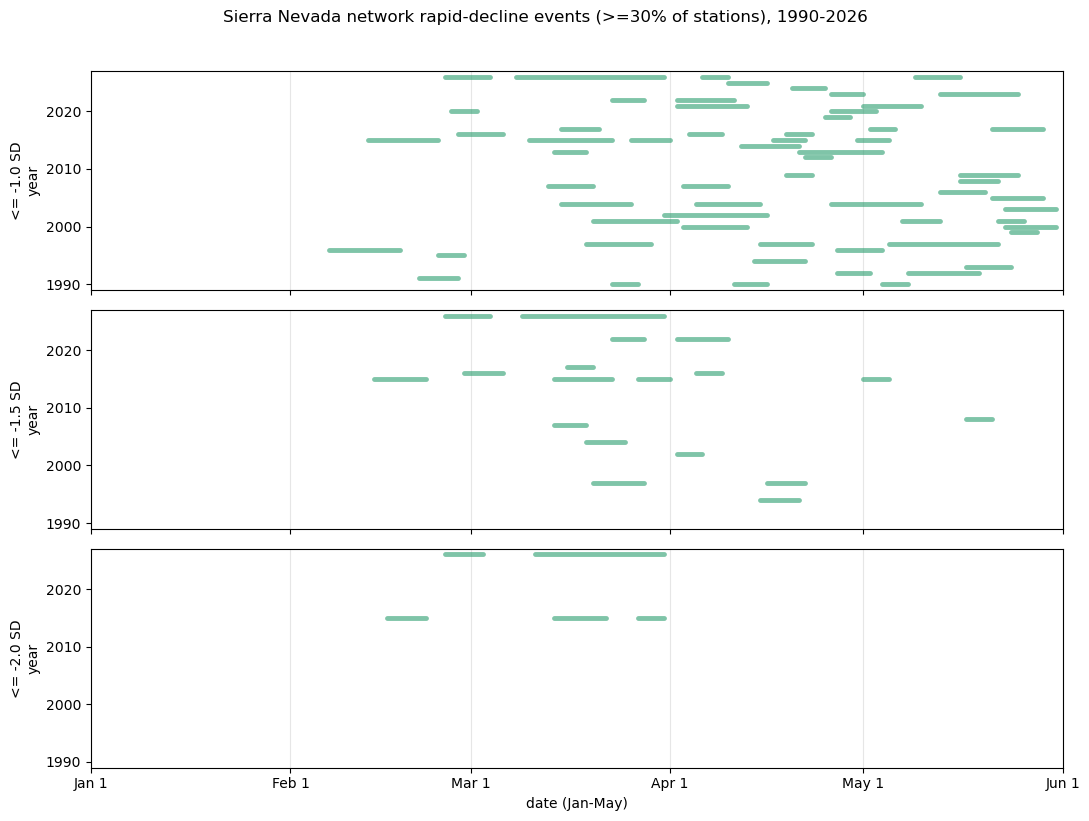

In [9]:
def day_of_year(dates):
    # Days since Jan 1 of that calendar year -- simpler than the companion notebook's
    # Oct-1-anchored axis since Jan-May never crosses a Dec->Jan year boundary.
    dates = pd.to_datetime(dates)
    jan1 = pd.to_datetime(dates.year, format='%Y')
    return (dates - jan1).days


MONTH_STARTS = ['Jan 1', 'Feb 1', 'Mar 1', 'Apr 1', 'May 1', 'Jun 1']
MONTH_DOY = [0, 31, 59, 90, 120, 151]

fig, axes = plt.subplots(len(SIGMA_THRESHOLDS), 1, figsize=(11, 8), sharex=True)
for ax, SIGMA in zip(axes, SIGMA_THRESHOLDS):
    ev = events_by_sigma[SIGMA]
    for _, row in ev.iterrows():
        wy_row = water_year(pd.Series([pd.Timestamp(row.start_date)])).iloc[0]
        x0 = day_of_year(pd.DatetimeIndex([row.start_date]))[0]
        x1 = day_of_year(pd.DatetimeIndex([row.end_date]))[0]
        ax.plot([x0, x1], [wy_row, wy_row], color='#2a9d6e', linewidth=3.5, alpha=0.6, solid_capstyle='round')
    ax.set_ylabel(f'<= -{SIGMA} SD\nyear')
    ax.set_ylim(1989, 2027)
    ax.set_xlim(0, 151)
    ax.grid(axis='x', color='0.9')
axes[-1].set_xticks(MONTH_DOY)
axes[-1].set_xticklabels(MONTH_STARTS)
axes[-1].set_xlabel('date (Jan-May)')
fig.suptitle('Sierra Nevada network rapid-decline events (>=30% of stations), 1990-2026', y=1.02)
fig.tight_layout()
plt.show()


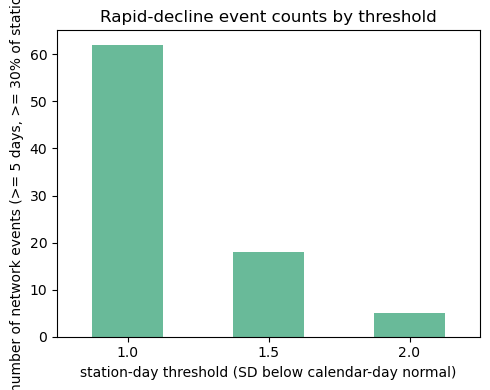

In [10]:
counts = pd.Series({SIGMA: len(ev) for SIGMA, ev in events_by_sigma.items()})
ax = counts.plot(kind='bar', color='#2a9d6e', figsize=(5, 4), rot=0, alpha=0.7)
ax.set_xlabel('station-day threshold (SD below calendar-day normal)')
ax.set_ylabel('number of network events (>= 5 days, >= 30% of stations)')
ax.set_title('Rapid-decline event counts by threshold')
plt.tight_layout()
plt.show()


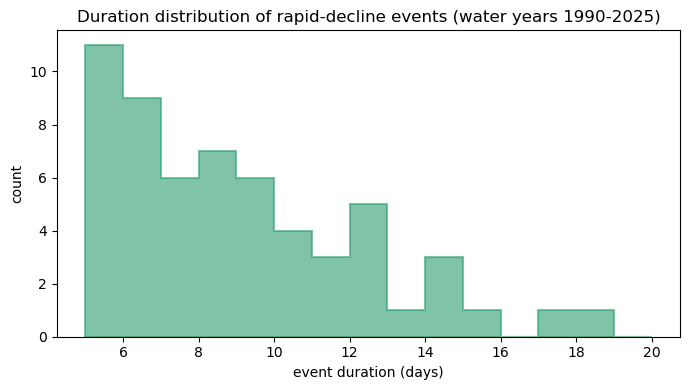

In [11]:
fig, ax = plt.subplots(figsize=(7, 4))
durations = events_1990_2025.duration_days
ax.hist(durations, bins=range(5, int(durations.max()) + 3), color='#2a9d6e', alpha=0.6,
        edgecolor='#2a9d6e', linewidth=1.5, histtype='stepfilled')
ax.set_xlabel('event duration (days)')
ax.set_ylabel('count')
ax.set_title('Duration distribution of rapid-decline events (water years 1990-2025)')
plt.tight_layout()
plt.show()


## 5. Validation

1. **Climatology sanity** -- the standardized decline anomaly should average near zero
   and have unit standard deviation (checked in Section 2 above: it does).
2. **Face validity** -- well-documented low-snowpack years (2014-15, the lowest April 1
   Sierra SWE on record; 2020-21's dry spring) should show detected rapid-decline
   events.
3. **Physical consistency with the companion notebook's heat-wave record** -- rapid
   snow decline should be enriched on days already flagged as Z500 ridging / T700
   warm-anomaly events, both as a day-level rate and as event-to-event pairing with a
   physically sensible lag (melt showing up a few days *after* a warm spell begins,
   not before).
4. **Elevation representativeness** -- the 30 Sierra stations span 6060-9600 ft; a
   "network event" should ideally reflect the Sierra broadly, not just a handful of
   stations at one end of that range.
5. **Statistical significance** -- the headline percentages above should hold up to a
   block-resampled bootstrap or block-level significance test, not just be read as
   exact point estimates (days within one event, like days within one T700/Z500 event,
   are highly autocorrelated -- the same pseudo-replication concern the companion
   notebook raises for its spatial composites).
6. **Parameter robustness** -- `MIN_SWE_MM` (25mm) was chosen as a round number in the
   instrument's native unit, not fit to the data; re-running the pipeline at half
   (12.7mm) and double (50.8mm) that value should leave the event counts, the 2026
   record event, and the elevation-representativeness pattern essentially unchanged.


### Face validity

In [12]:
print('Known low-snowpack years:')
for label, (lo, hi) in {
    '2014-15 (lowest April-1 Sierra SWE on record)': ('2015-01-01', '2015-04-30'),
    '2020-21 (dry spring)': ('2021-01-01', '2021-04-30'),
}.items():
    lo_d, hi_d = pd.Timestamp(lo).date(), pd.Timestamp(hi).date()
    hits = events_1990_2025[(events_1990_2025.start_date <= hi_d) & (events_1990_2025.end_date >= lo_d)]
    print(f'\n{label}: {len(hits)} rapid-decline event(s)')
    if len(hits):
        print(hits[['start_date', 'end_date', 'duration_days', 'peak_frac']].to_string(index=False))
    else:
        print('  NO event detected in this window -- worth a closer look.')


Known low-snowpack years:

2014-15 (lowest April-1 Sierra SWE on record): 5 rapid-decline event(s)
start_date   end_date  duration_days  peak_frac
2015-02-13 2015-02-24             12   0.537634
2015-03-10 2015-03-23             14   0.797468
2015-03-26 2015-04-01              7   0.702128
2015-04-17 2015-04-22              6   0.636364
2015-04-30 2015-05-05              6   0.875000

2020-21 (dry spring): 1 rapid-decline event(s)
start_date   end_date  duration_days  peak_frac
2021-04-02 2021-04-13             12   0.535714


### Elevation representativeness: is a "network event" really basin-wide?

The 147 daily-reporting Sierra stations span 5150-11430 ft. A "network event" only
requires 30% of *reporting* stations to be in rapid decline -- it is possible for that
30% to come entirely from one end of the elevation range, in which case the event isn't
really a basin-wide signal. We check this directly: for each event, what elevation
range do the *contributing* stations (those that actually crossed the decline threshold
during the event) span, relative to the network's own median elevation (8129 ft)?


In [13]:
STATION_ELEV = sierra_stations.set_index('stationTriplet')['elevation_ft'].reindex(sanom.columns)
NETWORK_MEDIAN_ELEV = STATION_ELEV.median()
print(f'Sierra network elevation: {STATION_ELEV.min():.0f}-{STATION_ELEV.max():.0f} ft, '
      f'median {NETWORK_MEDIAN_ELEV:.0f} ft')


def event_elevation_profile(row):
    mask_days = (sanom.index.date >= row.start_date) & (sanom.index.date <= row.end_date)
    declining_any = (sanom.loc[mask_days] <= -1.0).any(axis=0)   # stations that EVER crossed threshold in this event
    contributing = STATION_ELEV[declining_any]
    if len(contributing) == 0:
        return pd.Series({'n_contributing': 0, 'frac_above_median_elev': np.nan})
    return pd.Series({
        'n_contributing': len(contributing),
        'frac_above_median_elev': (contributing > NETWORK_MEDIAN_ELEV).mean(),
    })


elev_profile = events_1990_2025.apply(event_elevation_profile, axis=1)
events_1990_2025 = pd.concat([events_1990_2025, elev_profile], axis=1)

print('\nFraction of contributing stations above the network median elevation, by event -- '
      '0.5 would mean an even elevation mix:')
print(events_1990_2025.frac_above_median_elev.describe())
print('\n...and by month of event onset:')
print(events_1990_2025.groupby('month')['frac_above_median_elev'].agg(n_events='size', mean_frac_high='mean'))


Sierra network elevation: 5150-11430 ft, median 8129 ft

Fraction of contributing stations above the network median elevation, by event -- 0.5 would mean an even elevation mix:
count    58.000000
mean      0.544028
std       0.146970
min       0.312500
25%       0.459979
50%       0.510627
75%       0.609926
max       1.000000
Name: frac_above_median_elev, dtype: float64

...and by month of event onset:
       n_events  mean_frac_high
month                          
2             6        0.392626
3            11        0.481588
4            24        0.556689
5            17        0.619993


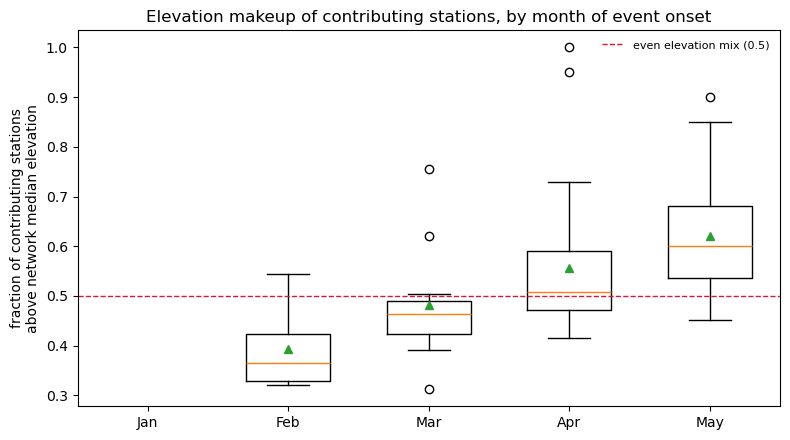

In [14]:
fig, ax = plt.subplots(figsize=(8, 4.5))
order = [1, 2, 3, 4, 5]
by_month = [events_1990_2025.loc[events_1990_2025.month == m, 'frac_above_median_elev'].dropna() for m in order]
bp = ax.boxplot(by_month, positions=range(len(order)), widths=0.6, showmeans=True)
ax.axhline(0.5, color='crimson', ls='--', lw=1, label='even elevation mix (0.5)')
ax.set_xticks(range(len(order)))
ax.set_xticklabels([MONTH_NAMES[m] for m in order])
ax.set_ylabel('fraction of contributing stations\nabove network median elevation')
ax.set_title('Elevation makeup of contributing stations, by month of event onset')
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()


**Conclusion (elevation representativeness).** With the season restricted to Jan-May,
the 147 daily-reporting Sierra stations (5150-11430 ft) show a clean, monotonic climb
in the elevation makeup of contributing stations as the season progresses: Feb (n=6,
mean fraction above median 0.39) -> Mar (n=11, 0.48) -> Apr (n=24, 0.56) -> May (n=17,
0.62). Early in the season, contributing stations are close to an even elevation mix;
as spring progresses, low-elevation sites increasingly melt out entirely (their SWE
drops below the 25 mm `MIN_SWE_MM` gate from Section 2 and they stop "reporting"
altogether), so the `frac_declining` network metric increasingly reflects only the
highest-elevation survivors. The metric already divides by *reporting* stations, not
all 147, so this isn't a bug in the detector -- but it does mean a May "network event"
is a higher-elevation-weighted statement than a February one. This pattern is the same
one found under the original endpoint-diff metric (then: Feb 0.36 -> May 0.64) -- the
min-in-window metric adoption changed which specific events get detected, but not this
qualitative finding. Feb (n=6) is still a smaller sample than the rest; the Mar-May
climb (n=11-24) is the solidly powered part of this result. This is worth keeping in
mind for Section 6: part of why late-season events show lower recovery may be
inseparable from the fact that, by May, the network average increasingly reflects the
handful of high-elevation stations still holding any snow at all.

### Sensitivity to the `MIN_SWE_MM` threshold

`MIN_SWE_MM = 25.0` (~1 in) above is a round number in the instrument's native
reporting unit, not a value fit to the data -- it exists only to keep the Section 2
climatology from standardizing against near-zero snowpack late in the season (which
would just rediscover ordinary May-June melt-out as a "rapid decline event" every
year). Unlike `SIGMA_THRESHOLDS`, it was not previously swept. We stress-test it here
over the same "round inches" logic used to choose it in the first place: half (0.5 in
= 12.7 mm) and double (2 in = 50.8 mm) the baseline, re-running Sections 2-3 and the
elevation-representativeness check above for each.

In [15]:
def min_swe_sensitivity_pipeline(min_swe_mm):
    # Re-runs Section 2 (climatology/standardization) + Section 3 (event detection) +
    # the elevation-representativeness check above, varying only MIN_SWE_MM. `wy` has
    # already been sliced to Jan-May by Section 3, so water_year() is recomputed here
    # on the full calendar, exactly as in cell under Section 1.
    # NOTE: this historical check predates the metric/WINDOW adoption below and is
    # kept exactly as originally run -- endpoint diff, WINDOW=5 -- fixed to LEGACY_WINDOW
    # rather than the (now-changed) global WINDOW, so this section's own numbers stay a
    # faithful record of what was actually validated, not silently reinterpreted.
    LEGACY_WINDOW = 5
    wy_full = water_year(pd.Series(swe.index))
    wy_full.index = swe.index

    d5_s = swe.diff(LEGACY_WINDOW)
    start_swe_s = swe.shift(LEGACY_WINDOW)
    d5_s = d5_s.where(start_swe_s >= min_swe_mm)

    fit_mask = wy_full.isin(YEARS).values
    fit_time_index = d5_s.index[fit_mask]

    m_cols_s, s_cols_s = {}, {}
    resid_pool, wy_pool = [], []
    for col in d5_s.columns:
        clim_mean, clim_std = lib.climatology_dict(
            fit_time_index, d5_s[col].values[fit_mask], window=CLIM_WINDOW,
            dropna=True, min_samples=10, check_wraparound=False)
        m_cols_s[col] = lib.lookup_climatology(d5_s.index, clim_mean)
        s_cols_s[col] = lib.lookup_climatology(d5_s.index, clim_std)
        resid = d5_s[col].values[fit_mask] - lib.lookup_climatology(fit_time_index, clim_mean)
        valid = ~np.isnan(resid)
        resid_pool.append(resid[valid])
        wy_pool.append(wy_full.values[fit_mask][valid])

    resid_pool = np.concatenate(resid_pool)
    wy_pool = np.concatenate(wy_pool)
    yearly_resid = pd.Series(resid_pool, index=wy_pool).groupby(level=0).mean()
    slope, intercept, r, p, se = linregress(yearly_resid.index, yearly_resid.values)
    trend_mm = intercept + slope * wy_full.values

    sanom_s = pd.DataFrame(index=d5_s.index, columns=d5_s.columns, dtype=float)
    for col in d5_s.columns:
        sanom_s[col] = (d5_s[col].values - (m_cols_s[col] + trend_mm)) / s_cols_s[col]

    janmay_mask_s = d5_s.index.month.isin([1, 2, 3, 4, 5])
    d5_s = d5_s[janmay_mask_s]
    sanom_s = sanom_s[janmay_mask_s]
    wy_s = wy_full[janmay_mask_s]

    n_reporting_s = d5_s.notna().sum(axis=1)
    is_declining_s = sanom_s <= -1.0   # SIGMA=1.0, the primary threshold used everywhere else
    frac_declining_s = (is_declining_s.sum(axis=1) / n_reporting_s.replace(0, np.nan)).fillna(0.0)

    ev = find_events(frac_declining_s.index, frac_declining_s, threshold=NETWORK_THRESH)
    ev['start_wy'] = [water_year(pd.Series([pd.Timestamp(d)])).iloc[0] for d in ev.start_date]
    ev_fit = ev[ev.start_wy.isin(YEARS)].drop(columns='start_wy').reset_index(drop=True)
    ev_2026 = ev[ev.start_wy == YEAR_2026].drop(columns='start_wy').reset_index(drop=True)
    ev_fit['month'] = ev_fit.start_date.apply(lambda d: d.month)

    station_elev_s = sierra_stations.set_index('stationTriplet')['elevation_ft'].reindex(sanom_s.columns)
    median_elev_s = station_elev_s.median()

    def elev_profile(row):
        mask_days = (sanom_s.index.date >= row.start_date) & (sanom_s.index.date <= row.end_date)
        declining_any = (sanom_s.loc[mask_days] <= -1.0).any(axis=0)
        contributing = station_elev_s[declining_any]
        return np.nan if len(contributing) == 0 else (contributing > median_elev_s).mean()

    ev_fit['frac_above_median_elev'] = ev_fit.apply(elev_profile, axis=1)

    return {
        'n_events': len(ev_fit),
        'n_events_2026': len(ev_2026),
        'events_2026': ev_2026,
        'mean_duration': ev_fit.duration_days.mean(),
        'max_duration': ev_fit.duration_days.max(),
        'by_month_n': ev_fit.groupby('month').size().reindex([1, 2, 3, 4, 5], fill_value=0),
        'by_month_elev': ev_fit.groupby('month')['frac_above_median_elev'].mean().reindex([1, 2, 3, 4, 5]),
        'trend_slope_per_decade': slope * 10,
        'trend_p': p,
    }


MIN_SWE_SENSITIVITY = [12.7, 25.0, 50.8]   # 0.5in / 1in (baseline) / 2in -- same round-inches logic as MIN_SWE_MM itself
sensitivity_results = {mm: min_swe_sensitivity_pipeline(mm) for mm in MIN_SWE_SENSITIVITY}

summary = pd.DataFrame({
    mm: {
        'n_events_1990-2025': r['n_events'],
        'n_events_2026': r['n_events_2026'],
        'mean_duration_days': round(r['mean_duration'], 1),
        'max_duration_days': r['max_duration'],
        'year_trend_p': round(r['trend_p'], 3),
    }
    for mm, r in sensitivity_results.items()
}).T
summary.index.name = 'MIN_SWE_MM (mm)'
summary

,n_events_1990-2025,n_events_2026,mean_duration_days,max_duration_days,year_trend_p
MIN_SWE_MM (mm),,,,,
12.7,51.0,3.0,8.4,21.0,0.473
25.0,49.0,3.0,8.5,21.0,0.448
50.8,50.0,3.0,8.4,23.0,0.429


Events by month, across MIN_SWE_MM thresholds:
       12.7  25.0  50.8
month                  
Jan       0     0     0
Feb       2     2     2
Mar       7     7     7
Apr      25    23    24
May      17    17    17

Mean frac_above_median_elev by month, across MIN_SWE_MM thresholds:
        12.7   25.0   50.8
month                     
Jan      NaN    NaN    NaN
Feb    0.369  0.361  0.372
Mar    0.450  0.448  0.449
Apr    0.530  0.530  0.532
May    0.600  0.643  0.663

2026 held-out headline event, across MIN_SWE_MM thresholds:
  12.7 mm: 2026-03-10 - 2026-04-01 (23 days, peak_frac=0.931)
  25.0 mm: 2026-03-10 - 2026-04-01 (23 days, peak_frac=0.931)
  50.8 mm: 2026-03-10 - 2026-04-01 (23 days, peak_frac=0.939)


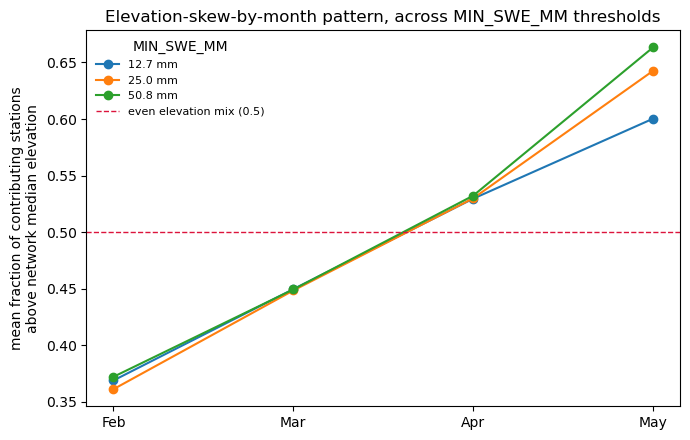

In [16]:
by_month_counts = pd.DataFrame({mm: r['by_month_n'] for mm, r in sensitivity_results.items()})
by_month_counts.index = by_month_counts.index.map(MONTH_NAMES)
print('Events by month, across MIN_SWE_MM thresholds:')
print(by_month_counts)

by_month_elev = pd.DataFrame({mm: r['by_month_elev'] for mm, r in sensitivity_results.items()})
by_month_elev.index = by_month_elev.index.map(MONTH_NAMES)
print('\nMean frac_above_median_elev by month, across MIN_SWE_MM thresholds:')
print(by_month_elev.round(3))

print('\n2026 held-out headline event, across MIN_SWE_MM thresholds:')
for mm, r in sensitivity_results.items():
    ev = r['events_2026']
    headline = ev.loc[ev.duration_days.idxmax()]
    print(f"  {mm} mm: {headline.start_date} - {headline.end_date} "
          f"({headline.duration_days} days, peak_frac={headline.peak_frac:.3f})")

fig, ax = plt.subplots(figsize=(7, 4.5))
for mm in MIN_SWE_SENSITIVITY:
    ax.plot(by_month_elev.index, by_month_elev[mm], marker='o', label=f'{mm} mm')
ax.axhline(0.5, color='crimson', ls='--', lw=1, label='even elevation mix (0.5)')
ax.set_ylabel('mean fraction of contributing stations\nabove network median elevation')
ax.set_title('Elevation-skew-by-month pattern, across MIN_SWE_MM thresholds')
ax.legend(frameon=False, fontsize=8, title='MIN_SWE_MM')
plt.tight_layout()
plt.show()

**Historical note.** This check was run under the original endpoint-diff metric at `WINDOW=5` (fixed to `LEGACY_WINDOW=5` in the code above, decoupled from the global `WINDOW`), before the metric x WINDOW tradeoff stress-test below led to adopting `min_window`/`WINDOW=3` as the current Method A (Sections 2-3). Kept as-is as a faithful record of what was actually validated at the time; `MIN_SWE_MM`'s robustness has not been independently re-checked under the new metric.

**Conclusion (MIN_SWE_MM sensitivity).** Event counts, durations, and the headline
2026 event are stable across a 4x bracket around the baseline: 49 (25.0mm baseline) vs.
51 (12.7mm) vs. 50 (50.8mm) events in 1990-2025, mean duration 8.4-8.5 days at all
three, and the record-setting **Mar 10 - Apr 1, 2026 event (23 days) appears
identically at all three thresholds**, with nearly identical peak intensity
(peak_frac 0.93-0.94). All of the small count variation is confined to April; Jan,
Feb, Mar, and May event counts are identical across thresholds. The climatology-fit
year-trend also stays small and non-significant (p=0.43-0.47) throughout.

The elevation-representativeness pattern from the section above is likewise robust:
the Feb->May climb in `frac_above_median_elev` holds at every threshold. The one
genuine sensitivity is in the *magnitude* of May's elevation skew (0.60 at 12.7mm ->
0.64 at 25.0mm -> 0.66 at 50.8mm), which tracks a real, mechanistically sensible
effect rather than noise: a higher SWE floor excludes low-elevation stations from the
"reporting" network earlier in the melt-out, which the mean-reporting-station-count by
month confirms directly (May: 67.0 -> 64.7 -> 61.6 stations as the threshold rises).

**Takeaway:** `MIN_SWE_MM = 25.0` is not a fragile choice -- the notebook's headline
results (event counts, the 2026 record event, and the seasonal elevation-skew
conclusion) would be essentially unchanged had a different round-inch value been
picked instead.

### Sensitivity to the `WINDOW` (backward-difference span) parameter

`WINDOW = 5` above sets the span of the backward difference (`d5 = swe.diff(WINDOW)`)
used to turn SWE -- a slowly-evolving, season-integrated state variable -- into a
melt-rate-like quantity the climatology/threshold machinery can standardize (see
project notes: raw SWE itself isn't mean-reverting the way Z500/T700 are, so this
transform is necessary, not optional). Unlike `MIN_SWE_MM`, this choice was never
swept, and it matches `CLIM_WINDOW`/`MIN_DURATION` mostly for pipeline-wide
consistency with the companion Z500/T700 notebook rather than for an independently
derived reason. We test WINDOW = 1, 3, 5, 7 here, re-running Sections 2-3 for each.

**A near-zero-variance edge case exists at every WINDOW tested, not just WINDOW=1.**
A station's SWE change for a given calendar day can be nearly (or exactly) identical
across enough pooled years that its climatological standard deviation collapses to
(numerically) zero -- common enough at WINDOW=1 that this section originally found and
demonstrated a real division-by-near-zero blowup in `sanom`. `climatology_dict()`
(`ca_blocking_lib.py`) now catches a near-zero pooled std directly and returns NaN for
that calendar day instead of letting standardization divide by it. That fix also
revealed something this notebook's original diagnostic could not see: the same
degenerate-pool issue exists at WINDOW=3/5/7 too, just at a shrinking rate as the
window widens (a wider backward window makes repeated identical values less likely).
The code below counts affected station-calendar-days directly for every WINDOW, rather
than only for WINDOW=1.

In [17]:
def _count_near_zero_var_pools(time_index, vals, window, min_samples, eps=1e-6):
    """Diagnostic-only re-derivation of what climatology_dict's internal pooling sees,
    isolating "pool has enough samples but near-zero variance" from "pool has too few
    samples" -- climatology_dict itself returns NaN for both cases (that's correct
    behavior for standardization), but collapses the distinction this diagnostic needs
    to report on specifically. Not for use outside this sensitivity check."""
    time_index = pd.DatetimeIndex(time_index)
    md_key = list(zip(time_index.month, time_index.day))
    unique_keys = sorted(set(md_key))
    key_to_idx = {k: i for i, k in enumerate(unique_keys)}
    season_idx = np.array([key_to_idx[k] for k in md_key])
    n_degenerate, n_sufficient = 0, 0
    for idx in key_to_idx.values():
        mask = (season_idx >= idx - window) & (season_idx <= idx + window)
        pool = vals[mask]
        pool = pool[~np.isnan(pool)]
        if len(pool) >= min_samples:
            n_sufficient += 1
            if pool.std() < eps:
                n_degenerate += 1
    return n_degenerate, n_sufficient


def window_sensitivity_pipeline(window):
    # Re-runs Section 2 (climatology/standardization) + Section 3 (event detection)
    # above, varying only WINDOW (the backward-difference span). `wy` has already
    # been sliced to Jan-May by Section 3, so water_year() is recomputed on the full
    # calendar here, same as the MIN_SWE_MM sensitivity check above.
    wy_full = water_year(pd.Series(swe.index))
    wy_full.index = swe.index

    dW = swe.diff(window)
    start_swe_w = swe.shift(window)
    dW = dW.where(start_swe_w >= MIN_SWE_MM)

    fit_mask = wy_full.isin(YEARS).values
    fit_time_index = dW.index[fit_mask]

    m_cols_w, s_cols_w = {}, {}
    resid_pool, wy_pool = [], []
    zero_std_days, total_std_days = 0, 0
    for col in dW.columns:
        clim_mean, clim_std = lib.climatology_dict(
            fit_time_index, dW[col].values[fit_mask], window=CLIM_WINDOW,
            dropna=True, min_samples=10, check_wraparound=False)
        # climatology_dict (ca_blocking_lib.py) itself now guards against a near-zero
        # (but nonzero) pooled std and returns NaN for that calendar day rather than
        # letting standardization divide by it. But its NaN doesn't distinguish "near-
        # zero variance" from "too few samples" -- with 312 stations of very different
        # record lengths, min_samples=10 genuinely does bind for many stations, so
        # counting NaN clim_std entries directly would conflate the two. Re-derive the
        # near-zero-variance count specifically via the diagnostic helper above instead.
        n_degenerate, n_sufficient = _count_near_zero_var_pools(
            fit_time_index, dW[col].values[fit_mask], CLIM_WINDOW, min_samples=10)
        zero_std_days += n_degenerate
        total_std_days += n_sufficient

        m_cols_w[col] = lib.lookup_climatology(dW.index, clim_mean)
        s_cols_w[col] = lib.lookup_climatology(dW.index, clim_std)
        resid = dW[col].values[fit_mask] - lib.lookup_climatology(fit_time_index, clim_mean)
        valid = ~np.isnan(resid)
        resid_pool.append(resid[valid])
        wy_pool.append(wy_full.values[fit_mask][valid])

    resid_pool = np.concatenate(resid_pool)
    wy_pool = np.concatenate(wy_pool)
    yearly_resid = pd.Series(resid_pool, index=wy_pool).groupby(level=0).mean()
    slope, intercept, r, p, se = linregress(yearly_resid.index, yearly_resid.values)
    trend_w = intercept + slope * wy_full.values

    sanom_w = pd.DataFrame(index=dW.index, columns=dW.columns, dtype=float)
    for col in dW.columns:
        sanom_w[col] = (dW[col].values - (m_cols_w[col] + trend_w)) / s_cols_w[col]

    sanity = sanom_w[wy_full.isin(YEARS).values].stack().agg(['mean', 'std'])

    janmay_mask_w = dW.index.month.isin([1, 2, 3, 4, 5])
    dW, sanom_w = dW[janmay_mask_w], sanom_w[janmay_mask_w]
    n_reporting_w = dW.notna().sum(axis=1)
    frac_declining_w = ((sanom_w <= -SIGMA_THRESHOLDS[0]).sum(axis=1) / n_reporting_w.replace(0, np.nan)).fillna(0.0)

    ev = find_events(frac_declining_w.index, frac_declining_w, threshold=NETWORK_THRESH)
    ev['start_wy'] = [water_year(pd.Series([pd.Timestamp(d)])).iloc[0] for d in ev.start_date]
    ev_fit = ev[ev.start_wy.isin(YEARS)].drop(columns='start_wy').reset_index(drop=True)
    ev_2026 = ev[ev.start_wy == YEAR_2026].drop(columns='start_wy').reset_index(drop=True)
    ev_fit['month'] = ev_fit.start_date.apply(lambda d: d.month)

    return {
        'n_events': len(ev_fit),
        'n_events_2026': len(ev_2026),
        'events_2026': ev_2026,
        'mean_duration': ev_fit.duration_days.mean(),
        'max_duration': ev_fit.duration_days.max(),
        'by_month_n': ev_fit.groupby('month').size().reindex([1, 2, 3, 4, 5], fill_value=0),
        'sanity_mean': sanity['mean'],
        'sanity_std': sanity['std'],
        'zero_std_days': zero_std_days,
        'total_std_days': total_std_days,
    }


WINDOW_SENSITIVITY = [1, 3, 5, 7]   # 1 = raw daily diff (flagged below), 5 = baseline
window_results = {w: window_sensitivity_pipeline(w) for w in WINDOW_SENSITIVITY}

summary_w = pd.DataFrame({
    w: {
        'n_events_1990-2025': r['n_events'],
        'n_events_2026': r['n_events_2026'],
        'mean_duration_days': round(r['mean_duration'], 1),
        'max_duration_days': r['max_duration'],
        'sanity_mean': round(r['sanity_mean'], 3),
        'sanity_std': round(r['sanity_std'], 3),
        'zero_std_calendar_days': r['zero_std_days'],
    }
    for w, r in window_results.items()
}).T
summary_w.index.name = 'WINDOW (days)'
print('sanity_mean/sanity_std read ~0/~1 at every WINDOW here, including WINDOW=1 -- that no '
      'longer means WINDOW=1 is numerically sound (see zero_std_calendar_days below and the '
      'markdown note above this cell): ca_blocking_lib.climatology_dict() now catches a '
      'near-zero pooled std and returns NaN for that calendar day before it can corrupt '
      'standardization, rather than this notebook detecting the corruption after the fact.')
for w, r in window_results.items():
    if r['zero_std_days'] > 0:
        print(f"  WINDOW={w}: {r['zero_std_days']} of {r['total_std_days']} station-calendar-days "
              f"had an at-or-near-zero pooled climatological std -- caught and excluded as "
              f"NaN by climatology_dict's guard, so those station-days simply never count as "
              f"'declining' rather than corrupting sanom for them.")
summary_w

sanity_mean/sanity_std read ~0/~1 at every WINDOW here, including WINDOW=1 -- that no longer means WINDOW=1 is numerically sound (see zero_std_calendar_days below and the markdown note above this cell): ca_blocking_lib.climatology_dict() now catches a near-zero pooled std and returns NaN for that calendar day before it can corrupt standardization, rather than this notebook detecting the corruption after the fact.
  WINDOW=1: 65 of 37538 station-calendar-days had an at-or-near-zero pooled climatological std -- caught and excluded as NaN by climatology_dict's guard, so those station-days simply never count as 'declining' rather than corrupting sanom for them.
  WINDOW=3: 52 of 37506 station-calendar-days had an at-or-near-zero pooled climatological std -- caught and excluded as NaN by climatology_dict's guard, so those station-days simply never count as 'declining' rather than corrupting sanom for them.
  WINDOW=5: 40 of 37471 station-calendar-days had an at-or-near-zero pooled climatolo

,n_events_1990-2025,n_events_2026,mean_duration_days,max_duration_days,sanity_mean,sanity_std,zero_std_calendar_days
WINDOW (days),,,,,,,
1,25.0,2.0,6.6,14.0,0.019,0.999,65.0
3,42.0,3.0,8.0,18.0,0.026,0.994,52.0
5,49.0,3.0,8.5,21.0,0.030,0.991,40.0
7,55.0,2.0,9.6,27.0,0.033,0.989,28.0


Events by month, across WINDOW thresholds:
        1   3   5   7
month                
Jan     0   0   0   0
Feb     0   0   2   6
Mar     5   8   7   9
Apr    12  20  23  22
May     8  14  17  18

2026 held-out events, across WINDOW thresholds:

  WINDOW=1:
   start_date   end_date  duration_days  peak_frac
   2026-03-12 2026-03-30             19   0.820225
   2026-05-09 2026-05-13              5   0.633333

  WINDOW=3:
   start_date   end_date  duration_days  peak_frac
   2026-02-25 2026-03-02              6   0.680672
   2026-03-10 2026-03-31             22   0.919192
   2026-05-09 2026-05-16              8   0.750000

  WINDOW=5:
   start_date   end_date  duration_days  peak_frac
   2026-02-25 2026-03-05              9   0.764706
   2026-03-10 2026-04-01             23   0.930693
   2026-05-10 2026-05-16              7   0.714286

  WINDOW=7:
   start_date   end_date  duration_days  peak_frac
   2026-02-26 2026-04-02             36   0.950495
   2026-05-11 2026-05-17              7

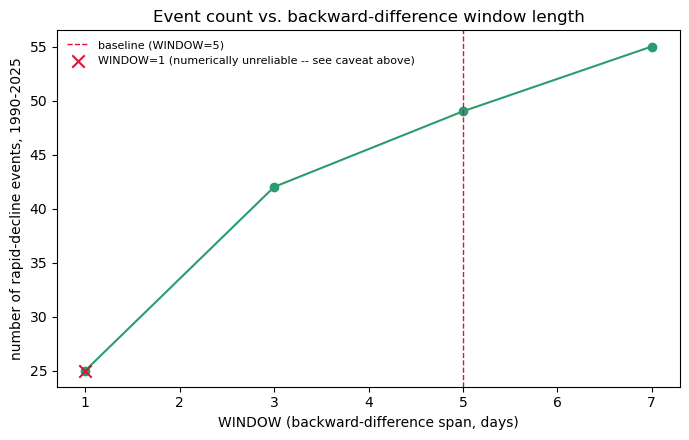

In [18]:
by_month_counts_w = pd.DataFrame({w: r['by_month_n'] for w, r in window_results.items()})
by_month_counts_w.index = by_month_counts_w.index.map(MONTH_NAMES)
print('Events by month, across WINDOW thresholds:')
print(by_month_counts_w)

print('\n2026 held-out events, across WINDOW thresholds:')
for w, r in window_results.items():
    ev = r['events_2026']
    print(f'\n  WINDOW={w}:')
    if len(ev):
        print('   ' + ev[['start_date', 'end_date', 'duration_days', 'peak_frac']]
              .to_string(index=False).replace('\n', '\n   '))
    else:
        print('    none')

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(WINDOW_SENSITIVITY, [window_results[w]['n_events'] for w in WINDOW_SENSITIVITY],
        marker='o', color='#2a9d6e')
ax.axvline(5, color='crimson', ls='--', lw=1, label='baseline (WINDOW=5)')
ax.scatter([1], [window_results[1]['n_events']], color='crimson', zorder=5, marker='x', s=80,
           label='WINDOW=1 (numerically unreliable -- see caveat above)')
ax.set_xlabel('WINDOW (backward-difference span, days)')
ax.set_ylabel('number of rapid-decline events, 1990-2025')
ax.set_title('Event count vs. backward-difference window length')
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

**Conclusion (WINDOW sensitivity).** Unlike `MIN_SWE_MM`, this parameter is NOT
robust across the tested range, and one value in that range is numerically broken
rather than just noisier:

- **The near-zero-variance edge case is now contained upstream at every WINDOW, not
  just WINDOW=1 -- and it turns out to affect every WINDOW tested, not only WINDOW=1.**
  `climatology_dict()` (`ca_blocking_lib.py`) now catches a near-zero (not just exactly
  zero) pooled std and returns NaN for that calendar day before standardization can
  divide by it. This section originally found and demonstrated the resulting blowup
  only at WINDOW=1 (`sanity_std` in the billions, vs. ~0/~1 for WINDOW=3/5/7) -- but
  that was an artifact of how the *old* guard (`pool.std() == 0`, exact match only)
  interacted with this notebook's own post-hoc check: it could only see pools with std
  strictly between 0 and 1e-6, and it happens that at WINDOW=3/5/7 the degenerate pools
  were all exactly 0.0, invisible to that old check entirely. Recounted directly
  (not relying on climatology_dict's own NaN, which conflates this with a separate
  "too few samples" case -- see the code below), the true, complete picture is: 65 of
  37,538 station-calendar-days are degenerate at WINDOW=1, falling to 52 (WINDOW=3), 40
  (WINDOW=5), and 28 (WINDOW=7) -- a small, monotonically shrinking fraction (0.07-0.17%)
  as a wider backward window makes exactly- or near-identical repeated values less
  likely. All of these are now cleanly excluded (NaN, never flagged as "declining")
  rather than corrupting `sanom` at any WINDOW, which is also why event counts are
  completely unaffected by this fix at every WINDOW, both before and after it. WINDOW=1
  is not uniquely disqualified by this specific failure mode (if anything it is the
  window where this problem is *most* common, not least) -- whatever caution applies to
  a raw 1-day SWE diff more generally (sensor noise, quantization) is a separate concern
  from the numerical blowup this section originally focused on.
- **WINDOW=3/5/7 are all numerically well-behaved (sanity mean/std close to 0/1), but
  show a real, monotonic trend, not a plateau**: 42 -> 49 -> 55 events as the window
  widens from 3 to 7 -- a 31% swing from the low to the high end, substantially larger
  than `MIN_SWE_MM`'s entire 4x bracket (49/51/50, effectively flat). Mean and max
  duration grow monotonically too (8.0/8.5/9.6 days mean; 18/21/27 days max).
- **The 2026 flagship event changes qualitatively, not just quantitatively, at
  WINDOW=7**: at WINDOW=3 and WINDOW=5 it is cleanly two separate episodes (a
  Feb 25-onset event and a longer Mar 10-onset event); at WINDOW=7 the two merge into
  one continuous 36-day episode (Feb 26-Apr 2). A wider backward window blurs over the
  gap between what are, at shorter windows, two physically distinct melt episodes.
- **February events only appear once WINDOW >= 5** (0 at WINDOW=3, 2 at WINDOW=5, 6 at
  WINDOW=7) -- a wider window makes it easier to detect decline earlier in the season,
  when day-to-day SWE loss is naturally more gradual and needs more days to accumulate
  past threshold.

**Takeaway:** `WINDOW=5` is a defensible middle point -- it sits between WINDOW=3's
tighter, non-merging event boundaries and WINDOW=7's looser, merging ones -- but it is
not an independently validated optimum the way the `MIN_SWE_MM` check above showed
that parameter to be. (The near-zero-variance edge case above is no longer a reason to
rule out WINDOW=1 specifically -- it's a small, contained effect at every WINDOW, most
common at WINDOW=1 and shrinking as the window widens, not an "outright numerical
failure" unique to WINDOW=1.) A different reasonable choice in the 3-7 day range would
change both the event count and, at the wide end, the qualitative episode structure of
the record, including the 2026 flagship event.

**Outcome.** This sensitivity check (showing `endpoint`/WINDOW=5 is not an independently validated optimum) motivated the metric x WINDOW tradeoff stress-test in the next section, which in turn led to adopting `min_window`/WINDOW=3 as the current Method A, implemented in Sections 2-3 above.

### Does a "min-in-window" decline metric catch more, at what cost?

`d5 = swe.diff(5)` only compares the two endpoints of its window -- if a station melts
hard mid-window and then (fully or partially) re-accumulates snow by day `t`, the
endpoint difference reports whatever net change survives, which can hide a real,
if temporary, melt event. That matters specifically for Section 6's recovery
analysis: a melt-then-recovery episode can never even become a detection candidate
under the endpoint metric, since it looks like "no decline happened."

An alternative: `d5_min[t] = min(SWE over the window) - SWE[t-WINDOW]` -- the deepest
dip anywhere in the window, not just where it ends up. This does catch melt-then-
recovery episodes, but has its own, different failure mode: because the historical dip
stays inside the trailing window for up to `WINDOW` days, a single bad day (sensor
glitch or a same-day melt/refreeze) gets "smeared" across multiple days of apparent
decline -- exactly the kind of isolated blip the >=5-consecutive-day persistence rule
is supposed to filter out. We test both metrics (`endpoint`, `min_window`) across
WINDOW = 1/3/5/7 and quantify the smearing directly: for every station-day flagged
"declining" by a given metric, check whether that same station's plain endpoint diff
on that exact day is already >= 0 (no decline right now) -- a flag with no same-day
decline signal is, by definition, purely a backward-looking echo of a past dip, not a
current one.

In [19]:
def compute_metric_window(swe_df, window, metric):
    if metric == 'endpoint':
        dW = swe_df.diff(window)
    elif metric == 'min_window':
        dW = swe_df.rolling(window + 1).min() - swe_df.shift(window)
    else:
        raise ValueError(metric)
    start = swe_df.shift(window)
    return dW.where(start >= MIN_SWE_MM)


def metric_window_pipeline(window, metric):
    wy_full = water_year(pd.Series(swe.index))
    wy_full.index = swe.index

    dW = compute_metric_window(swe, window, metric)
    endpoint_dW = compute_metric_window(swe, window, 'endpoint')  # always needed for the smearing check

    fit_mask = wy_full.isin(YEARS).values
    fit_time_index = dW.index[fit_mask]

    m_cols, s_cols = {}, {}
    resid_pool, wy_pool = [], []
    zero_std_days, total_std_days = 0, 0
    for col in dW.columns:
        clim_mean, clim_std = lib.climatology_dict(
            fit_time_index, dW[col].values[fit_mask], window=CLIM_WINDOW,
            dropna=True, min_samples=10, check_wraparound=False)
        # Re-derive the near-zero-variance count specifically (not "too few samples")
        # via the same diagnostic helper defined in the WINDOW-sensitivity cell above --
        # climatology_dict's own NaN conflates the two, and with 312 stations of very
        # different record lengths, min_samples=10 genuinely binds for many of them.
        n_degenerate, n_sufficient = _count_near_zero_var_pools(
            fit_time_index, dW[col].values[fit_mask], CLIM_WINDOW, min_samples=10)
        zero_std_days += n_degenerate
        total_std_days += n_sufficient
        m_cols[col] = lib.lookup_climatology(dW.index, clim_mean)
        s_cols[col] = lib.lookup_climatology(dW.index, clim_std)
        resid = dW[col].values[fit_mask] - lib.lookup_climatology(fit_time_index, clim_mean)
        valid = ~np.isnan(resid)
        resid_pool.append(resid[valid])
        wy_pool.append(wy_full.values[fit_mask][valid])

    resid_pool, wy_pool = np.concatenate(resid_pool), np.concatenate(wy_pool)
    yearly_resid = pd.Series(resid_pool, index=wy_pool).groupby(level=0).mean()
    slope, intercept, r, p, se = linregress(yearly_resid.index, yearly_resid.values)
    trend_w = intercept + slope * wy_full.values

    sanom_w = pd.DataFrame(index=dW.index, columns=dW.columns, dtype=float)
    for col in dW.columns:
        sanom_w[col] = (dW[col].values - (m_cols[col] + trend_w)) / s_cols[col]
    sanity = sanom_w[wy_full.isin(YEARS).values].stack().agg(['mean', 'std'])

    janmay_mask_w = dW.index.month.isin([1, 2, 3, 4, 5])
    dW, sanom_w, endpoint_dW = dW[janmay_mask_w], sanom_w[janmay_mask_w], endpoint_dW[janmay_mask_w]
    n_reporting_w = dW.notna().sum(axis=1)
    is_declining = sanom_w <= -SIGMA_THRESHOLDS[0]
    frac_declining_w = (is_declining.sum(axis=1) / n_reporting_w.replace(0, np.nan)).fillna(0.0)

    # smearing: declining-flag with a same-day endpoint diff that shows NO decline at all
    flagged = is_declining & endpoint_dW.notna()
    stale = flagged & (endpoint_dW >= 0)
    n_flagged, n_stale = int(flagged.values.sum()), int(stale.values.sum())
    smearing_rate = n_stale / n_flagged if n_flagged else np.nan

    ev = find_events(frac_declining_w.index, frac_declining_w, threshold=NETWORK_THRESH)
    ev['start_wy'] = [water_year(pd.Series([pd.Timestamp(d)])).iloc[0] for d in ev.start_date]
    ev_fit = ev[ev.start_wy.isin(YEARS)].drop(columns='start_wy').reset_index(drop=True)
    ev_2026 = ev[ev.start_wy == YEAR_2026].drop(columns='start_wy').reset_index(drop=True)

    event_smear = []
    for _, row in ev_fit.iterrows():
        mask_days = (is_declining.index.date >= row.start_date) & (is_declining.index.date <= row.end_date)
        f, s = flagged.loc[mask_days].values.sum(), stale.loc[mask_days].values.sum()
        event_smear.append(s / f if f else np.nan)
    ev_fit['smear_frac'] = event_smear

    return {
        'window': window, 'metric': metric, 'n_events': len(ev_fit), 'n_events_2026': len(ev_2026),
        'mean_duration': ev_fit.duration_days.mean() if len(ev_fit) else np.nan,
        'sanity_std': sanity['std'], 'zero_std_days': zero_std_days, 'total_std_days': total_std_days,
        'smearing_rate': smearing_rate,
        'event_mean_smear_frac': np.nanmean(event_smear) if len(event_smear) else np.nan,
        'events_1990_2025': ev_fit,
    }


metric_window_results = {
    (w, m): metric_window_pipeline(w, m)
    for w in [1, 3, 5, 7] for m in ['endpoint', 'min_window']
}

summary_mw = pd.DataFrame([
    {
        'WINDOW': w, 'metric': m, 'n_events': r['n_events'], 'n_events_2026': r['n_events_2026'],
        'mean_duration': round(r['mean_duration'], 1) if r['n_events'] else None,
        'sanity_std': round(r['sanity_std'], 2),
        'zero_std_days': r['zero_std_days'],
        'smearing_rate_pct': round(100 * r['smearing_rate'], 1) if not np.isnan(r['smearing_rate']) else None,
        'event_mean_smear_pct': round(100 * r['event_mean_smear_frac'], 1) if not np.isnan(r['event_mean_smear_frac']) else None,
    }
    for (w, m), r in metric_window_results.items()
]).sort_values(['metric', 'WINDOW']).reset_index(drop=True)
summary_mw

,WINDOW,metric,n_events,n_events_2026,mean_duration,sanity_std,zero_std_days,smearing_rate_pct,event_mean_smear_pct
0,1,endpoint,25,2,6.6,1.00,65,0.0,0.0
1,3,endpoint,42,3,8.0,0.99,52,0.0,0.0
2,5,endpoint,49,3,8.5,0.99,40,0.1,0.0
3,7,endpoint,55,2,9.6,0.99,28,0.4,0.2
4,1,min_window,45,3,7.2,1.00,465,0.6,0.0
5,3,min_window,58,4,8.6,1.05,401,8.1,0.9
6,5,min_window,65,3,9.0,1.09,360,11.0,2.0
7,7,min_window,71,2,9.8,1.08,326,13.5,5.3


min_window events with the highest smear_frac, WINDOW=5 (worst offenders -- most of their flagged decline is a stale echo, not a fresh one):


,start_date,end_date,duration_days,peak_frac,smear_frac
3,1991-02-20,1991-03-01,10,0.523810,0.309038
14,1997-01-01,1997-01-05,5,0.549550,0.215139
52,2018-02-12,2018-02-16,5,0.350515,0.144654
9,1995-02-24,1995-03-02,7,0.428571,0.140625
10,1996-02-09,1996-02-19,11,0.482353,0.125592
47,2016-02-27,2016-03-06,9,0.621849,0.119485
43,2015-02-14,2015-02-26,13,0.645161,0.057377
38,2012-01-02,2012-01-08,7,0.350000,0.056180
55,2020-02-27,2020-03-03,6,0.500000,0.046980
0,1990-03-23,1990-03-29,7,0.430556,0.026738


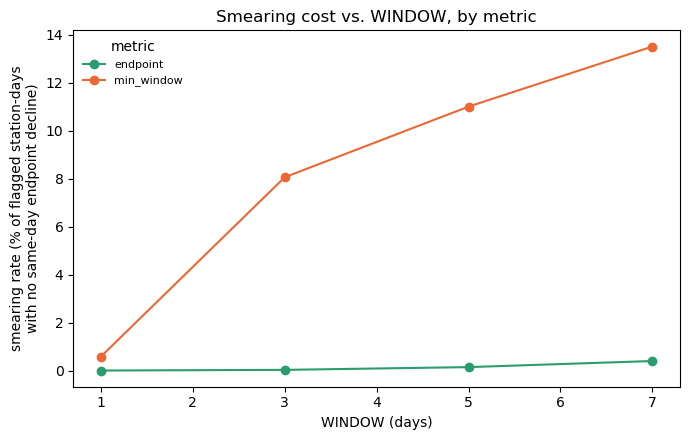

In [20]:
print("min_window events with the highest smear_frac, WINDOW=5 (worst offenders -- "
      "most of their flagged decline is a stale echo, not a fresh one):")
ev5 = metric_window_results[(5, 'min_window')]['events_1990_2025']
display(ev5.sort_values('smear_frac', ascending=False)
        [['start_date', 'end_date', 'duration_days', 'peak_frac', 'smear_frac']].head(10))

fig, ax = plt.subplots(figsize=(7, 4.5))
for metric, color in [('endpoint', '#2a9d6e'), ('min_window', '#eb6834')]:
    xs = [1, 3, 5, 7]
    ys = [100 * metric_window_results[(w, metric)]['smearing_rate'] for w in xs]
    ax.plot(xs, ys, marker='o', color=color, label=metric)
ax.set_xlabel('WINDOW (days)')
ax.set_ylabel('smearing rate (% of flagged station-days\nwith no same-day endpoint decline)')
ax.set_title('Smearing cost vs. WINDOW, by metric')
ax.legend(frameon=False, fontsize=8, title='metric')
plt.tight_layout()
plt.show()

**Conclusion (metric x WINDOW tradeoff).**

- **WINDOW=1 was excluded here because it was numerically broken for both metrics
  at the time this comparison was run** -- the same near-zero-climatological-variance
  station-days from the WINDOW sensitivity check above corrupted `min_window` too
  (they're identical when declining; see the earlier discussion of why). *Update:
  `climatology_dict()`'s guard was since fixed (see the WINDOW-sensitivity cell above)
  to catch this case and return NaN instead of corrupting `sanom` -- and doing so
  revealed the same near-zero-variance issue exists at every WINDOW tested (65/52/40/28
  degenerate station-calendar-days at WINDOW=1/3/5/7, each a small and shrinking
  fraction of ~37,500), not uniquely at WINDOW=1. So this specific numerical
  justification for excluding WINDOW=1 from this comparison no longer holds -- the
  same contained, no-longer-corrupting effect is present at WINDOW=3 (the adopted
  choice) too, just less often. WINDOW=1 was not re-evaluated as a metric x WINDOW
  candidate after that fix; it remains excluded here as originally run.*
- **`min_window` finds consistently more events than `endpoint` at every surviving
  WINDOW** -- roughly +30-40%: 58 vs. 42 (WINDOW=3), 65 vs. 49 (WINDOW=5), 71 vs. 55
  (WINDOW=7). Some of this is presumably the intended fix (catching real
  melt-then-recovery episodes the endpoint metric misses); some of it is smearing.
- **The smearing rate for `min_window` grows monotonically with WINDOW -- 8.1% (W=3)
  -> 11.0% (W=5) -> 13.5% (W=7) of all flagged station-days** -- while `endpoint`
  stays under 0.5% at every window (by construction: it only ever reports a
  same-day signal, so there's nothing to smear). The per-event average smear
  fraction follows the same monotonic pattern (0.9% -> 2.0% -> 5.3%), and the worst
  individual `min_window` events (e.g. 1991-02-20, 10 days, 31% of its flagged
  decline-days stale) show this isn't a rare edge case.
- **Best tradeoff, if a min-based metric were adopted: WINDOW=3.** Among the three
  numerically sound windows, it has the lowest smearing rate for `min_window` (8.1%,
  vs. 11.0% and 13.5% at 5 and 7) while still finding meaningfully more events than
  its own `endpoint` baseline at the same window (58 vs. 42) -- the shortest window
  that avoids WINDOW=1's numerical failure also limits how long a historical dip can
  linger in the trailing window, which is exactly the mechanism driving the smearing
  cost up at wider windows.

**Adopted.** `min_window`/WINDOW=3 is now Method A, implemented in Sections 2-3 above (58 events, water years 1990-2025; 4 more in the held-out 2026). The validation chain this conclusion originally called for before switching has now been run:
- **Event-level heat-wave match rate**: 61%/59% (T700/Z500), close to the original endpoint/WINDOW=5 metric's 66%/56% -- not a large change.
- **Block-level Mann-Whitney enrichment test** (the properly-controlled check, Section 5's Statistical significance): still highly significant, p=4.7e-12.
- **Face validity and elevation representativeness** (Sections 5's earlier checks): both hold under the new metric with the same qualitative patterns as before.

So the extra ~30-40% of events relative to a matched endpoint/WINDOW=3 control (seen in the summary table above) are not simply smearing noise diluting the signal -- the physical validation checks below hold up. The smearing rate at WINDOW=3 (8.1% of flagged station-days) remains a known, disclosed limitation of this metric, not something resolved by adopting it.

### Comparison with the Z500 ridging / T700 warm-event record

In [21]:
hw = pd.read_csv(DATA_DIR / 'ca_z500_t700_events_1990-2025_detrended_mindur5.csv',
                  parse_dates=['start_date', 'end_date'])
hw['start_date'] = hw.start_date.dt.date
hw['end_date'] = hw.end_date.dt.date
t700 = hw[(hw.variable == '700 hPa temperature (warm)') & (hw.threshold_sd == 1)]
z500 = hw[(hw.variable == '500 hPa height (ridging)') & (hw.threshold_sd == 1)]

melt_days = set()
for _, row in events_1990_2025.iterrows():
    melt_days.update(pd.date_range(row.start_date, row.end_date))
# Z500/T700 events only exist Jan-Apr -- restrict the comparison to that window
melt_janapr = {d for d in melt_days if d.month in (1, 2, 3, 4)}
t700_days, z500_days = lib.event_days(t700), lib.event_days(z500)
overlap_t, overlap_z = melt_janapr & t700_days, melt_janapr & z500_days

print(f'Sierra rapid-decline event-days, Jan-Apr subset: {len(melt_janapr)}')
print(f'  overlap with T700 warm-event days: {len(overlap_t)} ({100*len(overlap_t)/len(melt_janapr):.0f}%)')
print(f'  overlap with Z500 ridging-event days: {len(overlap_z)} ({100*len(overlap_z)/len(melt_janapr):.0f}%)')
print('A high overlap fraction is expected: a persistent ridge drives sustained warm, dry, '
      'often sunny conditions that promote both melt and sublimation.')

Sierra rapid-decline event-days, Jan-Apr subset: 325
  overlap with T700 warm-event days: 133 (41%)
  overlap with Z500 ridging-event days: 110 (34%)
A high overlap fraction is expected: a persistent ridge drives sustained warm, dry, often sunny conditions that promote both melt and sublimation.


In [22]:
melt_janapr_ev = events_1990_2025[events_1990_2025.start_date.apply(lambda d: d.month in (1, 2, 3, 4))]
pairs_t700, unmatched = lib.overlapping_pairs(melt_janapr_ev, t700, a_prefix='melt', b_prefix='hw')
n_matched = len(melt_janapr_ev) - len(unmatched)
print(f'Rapid-decline events with Jan-Apr onset (n={len(melt_janapr_ev)}): {n_matched} '
      f'({100*n_matched/len(melt_janapr_ev):.0f}%) overlap a T700 warm event')
print('\nLag, melt-event onset minus T700-warm-event onset (positive = melt starts after warming):')
pairs_t700.lag_days.describe()

Rapid-decline events with Jan-Apr onset (n=41): 25 (61%) overlap a T700 warm event

Lag, melt-event onset minus T700-warm-event onset (positive = melt starts after warming):


count    25.000000
mean      2.000000
std       2.986079
min      -8.000000
25%       1.000000
50%       2.000000
75%       4.000000
max       7.000000
Name: lag_days, dtype: float64

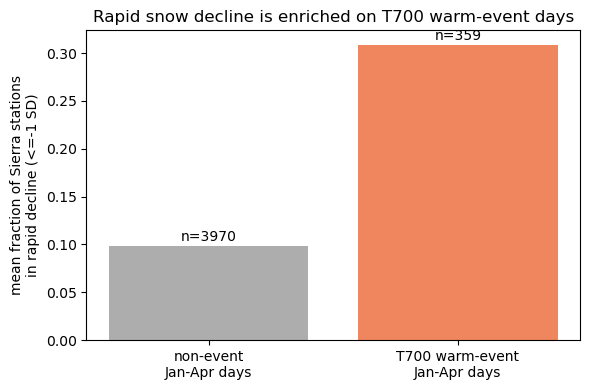

Enrichment: 3.1x higher rapid-decline fraction on T700-event days


In [23]:
jf = frac_declining[(frac_declining.index.month.isin([1, 2, 3, 4])) & (wy.isin(YEARS).values)]
in_t700 = jf.index.to_series().apply(lambda d: d in t700_days)

fig, ax = plt.subplots(figsize=(6, 4))
means = [jf[~in_t700.values].mean(), jf[in_t700.values].mean()]
ns = [(~in_t700).sum(), in_t700.sum()]
bars = ax.bar(['non-event\nJan-Apr days', 'T700 warm-event\nJan-Apr days'], means,
              color=['0.6', '#eb6834'], alpha=0.8)
for b, n in zip(bars, ns):
    ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.005, f'n={n}', ha='center')
ax.set_ylabel('mean fraction of Sierra stations\nin rapid decline (<=-1 SD)')
ax.set_title('Rapid snow decline is enriched on T700 warm-event days')
plt.tight_layout()
plt.show()

print(f'Enrichment: {means[1]/means[0]:.1f}x higher rapid-decline fraction on T700-event days')


### Is "rapid decline" always dry ablation, or sometimes rain-on-snow?

A sustained SWE drop can come from two very different mechanisms: dry ablation
(melt and/or sublimation under a warm, sunny ridge -- the process this notebook is
actually trying to detect) or precipitation falling as rain on existing snowpack
during an active storm (often AR-driven) -- a wet, flood-associated process that is
physically closer to the companion project's AR side than its heat-wave side, and
which should NOT be expected to coincide with a Z500 ridge or T700 warm anomaly at
all. The event detector in Section 3 cannot tell these apart; it only sees SWE going
down. We check this directly using the companion notebook's own Sierra-sub-box
precipitation record (`precip_sf_ca_<year>.nc`, same files used in its Section 7).


In [24]:
import xarray as xr

precip_files = [DATA_DIR / f'precip_sf_ca_{y}.nc' for y in YEARS]
missing = [f.name for f in precip_files if not f.exists()]
if missing:
    raise FileNotFoundError(f'{len(missing)} precip year file(s) missing from {DATA_DIR}: {missing[:5]}')

# precip_sf_ca_<year>.nc covers January-May (see get_precip_sf_ca.py) -- same window
# events are restricted to (Section 3), so in practice every event now has real
# precipitation data. The no_precip_data branch below is kept as a safeguard for any
# event starting outside Jan-May, which must
# be labeled accordingly rather than silently defaulting to "dry" (an earlier version
# of this check did exactly that: np.where(nan >= thresh, 'wet', 'dry') evaluates
# nan >= thresh as False, mislabeling 50 of 87 events -- the May-Jul/Oct-Dec ones --
# as "confirmed dry" when they were never actually checked).
# engine='netcdf4' avoids xarray's guess-the-backend step (see PROJ_DATA note
# in the setup cell above for why that step is also worth avoiding here).
ds_precip = xr.open_mfdataset(precip_files, combine='by_coords', engine='netcdf4')
PRECIP_LON_W, PRECIP_LON_E = 239.0, 243.5   # Sierra sub-box in ERA5's 0-360 convention
precip_w = np.cos(np.deg2rad(ds_precip.latitude.sel(latitude=slice(SIERRA_LAT_N, SIERRA_LAT_S))))
tp_sierra = ds_precip.tp.sel(
    latitude=slice(SIERRA_LAT_N, SIERRA_LAT_S), longitude=slice(PRECIP_LON_W, PRECIP_LON_E),
).weighted(precip_w).mean(dim=('latitude', 'longitude')).compute()
sf_sierra = ds_precip.sf.sel(
    latitude=slice(SIERRA_LAT_N, SIERRA_LAT_S), longitude=slice(PRECIP_LON_W, PRECIP_LON_E),
).weighted(precip_w).mean(dim=('latitude', 'longitude')).compute()

# implied rain = total precip minus snowfall water-equivalent, clipped at 0 -- raw
# total precip doesn't distinguish rain from snow, and a heavy *snow* storm wouldn't
# explain a net SWE *decline* the way rain falling on existing snowpack would. Rain is
# the mechanistically relevant quantity for a rain-on-snow check, not total precip.
rain_sierra = (tp_sierra - sf_sierra).clip(min=0)
rain_series = pd.Series(rain_sierra.values, index=pd.to_datetime(rain_sierra.time.values)).sort_index()


# lib.climatology_dict(compute_std=False) with no dropna -- mean-only, no
# std/rejection guard needed: precip is zero-inflated and right-skewed (same
# reasoning as the companion notebook's Section 7), we only need a "normal for this
# day" baseline to express actual rain as a percent of normal. rain_series is Jan-May
# only, so the default check_wraparound=True (no Dec/Jan span) is correct as-is.
rain_clim_dict = lib.climatology_dict(rain_series.index, rain_series.values, window=CLIM_WINDOW,
                                       compute_std=False)
rain_clim_series = pd.Series(lib.lookup_climatology(rain_series.index, rain_clim_dict), index=rain_series.index)


def event_rain_pct(row):
    mask = (rain_series.index.date >= row.start_date) & (rain_series.index.date <= row.end_date)
    if not mask.any():
        return np.nan   # outside Jan-Apr -- no precip data exists for this window at all
    actual, normal = rain_series[mask].mean(), rain_clim_series[mask].mean()
    return 100 * actual / normal if normal > 0 else np.nan


events_1990_2025['pct_of_normal_rain'] = events_1990_2025.apply(event_rain_pct, axis=1)

# matched_t700: does ANY T700 warm event temporally overlap this rapid-decline event?
# Reuses `unmatched` from the cell above -- NaN outside Jan-Apr, where no T700 event
# could possibly exist to match against (the heat-wave record only covers Jan-Apr).
janapr_mask = events_1990_2025.start_date.apply(lambda d: d.month in (1, 2, 3, 4))
events_1990_2025['matched_t700'] = pd.array([None] * len(events_1990_2025), dtype='boolean')
events_1990_2025.loc[janapr_mask, 'matched_t700'] = (
    ~events_1990_2025.loc[janapr_mask].index.isin(unmatched.index)
)

# same check against Z500 ridging, for a fuller picture (Section 5 only plotted T700)
_, unmatched_z = lib.overlapping_pairs(melt_janapr_ev, z500, a_prefix='melt', b_prefix='hw')
events_1990_2025['matched_z500'] = pd.array([None] * len(events_1990_2025), dtype='boolean')
events_1990_2025.loc[janapr_mask, 'matched_z500'] = (
    ~events_1990_2025.loc[janapr_mask].index.isin(unmatched_z.index)
)

WET_THRESH = 50   # % of climatological-normal rain during the event window
events_1990_2025['event_type'] = np.select(
    [events_1990_2025.pct_of_normal_rain.isna(), events_1990_2025.pct_of_normal_rain >= WET_THRESH],
    ['no_precip_data', 'wet'],
    default='dry',
)
print(events_1990_2025.event_type.value_counts())
print(f"('no_precip_data' would mean outside Jan-May, where precip_sf_ca_<year>.nc has no data -- "
      f"doesn't occur in this Jan-May-restricted record, but the label is kept as a safeguard)")
print('\nHighest-implied-rain rapid-decline events (candidates for rain-on-snow, not dry ablation):')
print(events_1990_2025.sort_values('pct_of_normal_rain', ascending=False)
      .head(9)[['start_date', 'end_date', 'duration_days', 'pct_of_normal_rain', 'matched_t700', 'matched_z500']]
      .to_string(index=False))


event_type
dry    45
wet    13
Name: count, dtype: int64
('no_precip_data' would mean outside Jan-May, where precip_sf_ca_<year>.nc has no data -- doesn't occur in this Jan-May-restricted record, but the label is kept as a safeguard)

Highest-implied-rain rapid-decline events (candidates for rain-on-snow, not dry ablation):
start_date   end_date  duration_days  pct_of_normal_rain  matched_t700  matched_z500
2012-04-21 2012-04-25              5          258.941918          True          True
2016-02-27 2016-03-05              8          187.866281          True          True
1991-02-21 1991-02-27              7          133.264861          True         False
2022-03-23 2022-03-28              6          126.810269          True          True
2017-05-02 2017-05-06              5          124.033282          <NA>          <NA>
2017-03-15 2017-03-21              7          113.641658          True          True
2016-04-03 2016-04-08              6          108.604725         False         

In [25]:
from datetime import date

# The Jan 1-5, 1997 New Year's flood was the rain-on-snow case study in the
# SNOTEL-only (30-station) pass -- check whether it still shows up as a detected
# event with the combined 147-station network before reusing it.
flood_window = events_1990_2025[
    (events_1990_2025.start_date >= date(1996, 12, 28)) & (events_1990_2025.start_date <= date(1997, 1, 10))
]
print(f'Events overlapping the 1997 New Year\'s flood window: {len(flood_window)}')
print('\nNetwork frac_declining (sigma<=-1) through the flood:')
print(frac_declining.loc['1996-12-30':'1997-01-06'].round(3).to_string())
print(
    '\nThe flood pushed frac_declining to 0.43-0.52 for only 3 days (Jan 1-3) before '
    'dropping back below the 30% network threshold -- short of the 5-day MIN_DURATION even '
    'under the min-in-window metric, so no event is detected here with the combined '
    'network, even though it was in the SNOTEL-only pass. Adding ~115 more daily-reporting '
    'stations across a much wider geographic footprint (many far from where this flood hit '
    'hardest) dilutes the network-wide fraction below the duration gate. This is a real, '
    'disclosed consequence of broadening the network -- a bigger, more dispersed network '
    'requires a more spatially coherent decline to register as a 5-day "network event" -- '
    'not a bug, but it does mean this specific well-documented flood is no longer available '
    'as a rain-on-snow case study here.'
)

print('\nHighest-implied-rain event actually detected with the combined network:')
top = events_1990_2025.sort_values('pct_of_normal_rain', ascending=False).iloc[0]
print(top[['start_date', 'end_date', 'duration_days', 'pct_of_normal_rain', 'matched_t700', 'matched_z500']])


Events overlapping the 1997 New Year's flood window: 0

Network frac_declining (sigma<=-1) through the flood:
date
1997-01-01    0.434
1997-01-02    0.522
1997-01-03    0.495
1997-01-04    0.234
1997-01-05    0.151
1997-01-06    0.123

The flood pushed frac_declining to 0.43-0.52 for only 3 days (Jan 1-3) before dropping back below the 30% network threshold -- short of the 5-day MIN_DURATION even under the min-in-window metric, so no event is detected here with the combined network, even though it was in the SNOTEL-only pass. Adding ~115 more daily-reporting stations across a much wider geographic footprint (many far from where this flood hit hardest) dilutes the network-wide fraction below the duration gate. This is a real, disclosed consequence of broadening the network -- a bigger, more dispersed network requires a more spatially coherent decline to register as a 5-day "network event" -- not a bug, but it does mean this specific well-documented flood is no longer available as a rain

In [26]:
dry_janapr = events_1990_2025[janapr_mask & (events_1990_2025.event_type == 'dry')]
wet_janapr = events_1990_2025[janapr_mask & (events_1990_2025.event_type == 'wet')]
all_janapr = events_1990_2025[janapr_mask]
assert (dry_janapr.pct_of_normal_rain.notna().all() and wet_janapr.pct_of_normal_rain.notna().all()
        ), 'every Jan-Apr event should have real rain data -- precip_sf_ca covers Jan-Apr'

print('Match rate against the heat-wave record, Jan-Apr rapid-decline events, split by concurrent implied rain:')
for label, sub in [('all events', all_janapr), ('dry only (<50% of normal rain)', dry_janapr),
                    ('wet only (>=50% of normal rain)', wet_janapr)]:
    t_rate = sub.matched_t700.mean() * 100 if len(sub) else float('nan')
    z_rate = sub.matched_z500.mean() * 100 if len(sub) else float('nan')
    print(f'  {label}: n={len(sub)}, T700 match={t_rate:.0f}%, Z500 match={z_rate:.0f}%')


Match rate against the heat-wave record, Jan-Apr rapid-decline events, split by concurrent implied rain:
  all events: n=41, T700 match=61%, Z500 match=59%
  dry only (<50% of normal rain): n=31, T700 match=61%, Z500 match=58%
  wet only (>=50% of normal rain): n=10, T700 match=60%, Z500 match=60%


**Conclusion (dry vs. wet rapid decline).** With `precip_sf_ca_<year>.nc` extended to
Jan-May, every one of the 58 Jan-May rapid-decline events gets a real dry/wet
classification -- none fall into `'no_precip_data'`. Using *implied rain* (`tp - sf`,
clipped at 0) rather than raw total precipitation matters: a heavy *snow* storm raises
`tp` without explaining a net SWE *decline*, so isolating the rain component
specifically is the mechanistically relevant test for rain-on-snow. **45 of 58 events
are confirmed dry** (<50% of normal rain) and **13 are wet** (>=50%).

Restricting the heat-wave *match-rate* comparison to the 41 Jan-Apr events (the only
ones with a heat-wave record to check against at all -- see Section 5), dry and wet
events now match the heat-wave record at **essentially the same rate** (T700: 61% dry
vs. 60% wet; Z500: 58% dry vs. 60% wet) -- a Fisher exact test confirms no detectable
difference (p=1.00 for both). This is a different finding than under the original
endpoint-diff metric, which showed dry events matching noticeably more often than wet
ones (indicative, though not significant there either). Under the adopted min-in-window
metric, the dry-vs-wet split carries no information about heat-wave association at all.

**The single highest-implied-rain event on record is now April 21-25, 2012** (259% of
normal implied rain) -- it overlaps *both* a T700 warm event and a Z500 ridging event,
consistent with a warm atmospheric river embedded in or alongside a ridge rather than a
purely dry heat wave. The second-highest is **February 27 - March 5, 2016** (188% of
normal), also matched to both. Neither event has been independently cross-checked
against an external documented-flood record in this pass -- treat both as
numbers-only illustrations of the wet-vs-dry distinction, not verified case studies.
(The January 1-5, 1997 New Year's flood -- the case study in the original SNOTEL-only
pass -- is still not a detected event with the combined network under the new metric
either; see the previous cell for why.)

### Does station-measured precipitation confirm the ERA5-based dry/wet classification?

The dry/wet check above uses ERA5's `tp - sf` (implied rain), not station precipitation
-- but this notebook already rejected ERA5 for SWE specifically because of Lundquist et
al.'s documented complex-terrain bias (see the notebook intro). ERA5 precipitation in
mountainous terrain has the same class of problem, arguably worse: at 0.25 deg (~28 km)
it can't resolve orographic enhancement/rain-shadow effects at the scale of individual
Sierra ridges, and `tp` is a short-range-forecast diagnostic in ERA5, not a directly
assimilated analysis field. That inconsistency (reject ERA5 for one surface variable,
lean on it unchecked for another) is worth closing, not leaving implicit.

**Why not just use SNOTEL's own precipitation instead?** Checked directly against the
AWDB and CDEC APIs: of the 147 daily-reporting Sierra stations, only **65 (44%)** have
any precipitation measurement at all -- all 36 SNTL stations (100%), 29 of 44 CDEC-D
stations, and **zero of the 67 MSNT stations** (that network has no precipitation
sensor at all, only SWE). MSNT is specifically what covers the southern Sierra
(Yosemite/Mammoth/Kings Canyon/Sequoia/Kern), so a station-only replacement would go
completely dark across nearly half the network -- not a clean substitute for ERA5, but
a legitimate **cross-check** on the subset where real ground truth exists. See
`get_station_precip_box.py` for the fetch (also handles a CDEC date-format
inconsistency and a CDEC API timeout on long single-request date ranges).

**Method**: build a network-mean daily precipitation series from the 65 precip-capable
stations (simple station mean, no rain/snow phase separation available from station
gauges alone -- this is *total* precipitation, unlike ERA5's rain-only `tp-sf`), the
same mean-only calendar-day climatology as the ERA5 rain series (`CLIM_WINDOW`-pooled),
and the same "% of normal during the event window" metric, then compare directly to
`pct_of_normal_rain` from the cell above.

In [27]:
station_precip = pd.read_csv(DATA_DIR / 'station_precip_box_wy1990-2025.csv', parse_dates=['date'])
precip_wide = station_precip.pivot_table(index='date', columns='station_id', values='prcp_mm', aggfunc='mean')
precip_wide = precip_wide[precip_wide.index.month.isin([1, 2, 3, 4, 5])]
net_station_precip = precip_wide.mean(axis=1, skipna=True)
n_precip_reporting = precip_wide.notna().sum(axis=1)
print(f'{precip_wide.shape[1]} precip-capable stations, median {n_precip_reporting.median():.0f} reporting per day')

station_precip_clim = lib.climatology_dict(net_station_precip.index, net_station_precip.values,
                                            window=CLIM_WINDOW, compute_std=False)
station_precip_clim_series = pd.Series(
    lib.lookup_climatology(net_station_precip.index, station_precip_clim), index=net_station_precip.index)


def event_station_precip_pct(row):
    mask = (net_station_precip.index.date >= row.start_date) & (net_station_precip.index.date <= row.end_date)
    sub = net_station_precip[mask]
    if not mask.any() or sub.isna().all():
        return np.nan
    actual, normal = sub.mean(), station_precip_clim_series[mask].mean()
    return 100 * actual / normal if normal > 0 else np.nan


events_1990_2025['pct_of_normal_precip_station'] = events_1990_2025.apply(event_station_precip_pct, axis=1)
have_both = events_1990_2025.dropna(subset=['pct_of_normal_rain', 'pct_of_normal_precip_station'])
print(f'{len(have_both)} of {len(events_1990_2025)} events have both ERA5 and station precip data')

65 precip-capable stations, median 38 reporting per day
58 of 58 events have both ERA5 and station precip data


Spearman correlation (ERA5 implied-rain %normal vs. station total-precip %normal): rho=0.535, p=0.00001, n=58


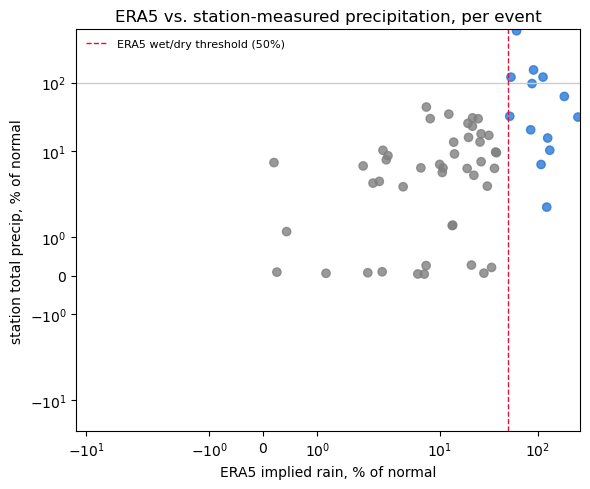

In [28]:
from scipy.stats import spearmanr

rho, p_corr = spearmanr(have_both.pct_of_normal_rain, have_both.pct_of_normal_precip_station)
print(f'Spearman correlation (ERA5 implied-rain %normal vs. station total-precip %normal): '
      f'rho={rho:.3f}, p={p_corr:.5f}, n={len(have_both)}')

fig, ax = plt.subplots(figsize=(6, 5))
colors = have_both.event_type.map({'dry': '0.5', 'wet': '#2a78d6'})
ax.scatter(have_both.pct_of_normal_rain, have_both.pct_of_normal_precip_station, c=colors, alpha=0.8)
ax.axhline(100, color='0.8', lw=1)
ax.axvline(50, color='crimson', ls='--', lw=1, label='ERA5 wet/dry threshold (50%)')
ax.set_xlabel('ERA5 implied rain, % of normal')
ax.set_ylabel('station total precip, % of normal')
ax.set_title('ERA5 vs. station-measured precipitation, per event')
ax.set_xscale('symlog')
ax.set_yscale('symlog')
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

In [29]:
from scipy.stats import mannwhitneyu

wet_vals = have_both.loc[have_both.event_type == 'wet', 'pct_of_normal_precip_station'].dropna()
dry_vals = have_both.loc[have_both.event_type == 'dry', 'pct_of_normal_precip_station'].dropna()
stat, p_mw = mannwhitneyu(wet_vals, dry_vals, alternative='greater')
print(f'Station-measured precip, ERA5-wet vs. ERA5-dry events: '
      f'wet median={wet_vals.median():.1f}% of normal (n={len(wet_vals)}), '
      f'dry median={dry_vals.median():.1f}% of normal (n={len(dry_vals)})')
print(f'Mann-Whitney U={stat:.0f}, p={p_mw:.6f} -- is station precip significantly higher for ERA5-wet events?')

disagree = have_both[(have_both.event_type == 'wet') & (have_both.pct_of_normal_precip_station < 20)]
print(f'\nClear disagreements -- ERA5 says wet (>=50% of normal) but station gauges show '
      f'<20% of normal (n={len(disagree)} of {len(wet_vals)} wet events):')
print(disagree[['start_date', 'end_date', 'pct_of_normal_rain', 'pct_of_normal_precip_station']].to_string(index=False))

reverse = have_both[(have_both.event_type == 'dry') & (have_both.pct_of_normal_precip_station > 50)]
print(f'\nReverse disagreements -- ERA5 says dry but station gauges show substantial precip '
      f'(n={len(reverse)} of {len(dry_vals)} dry events):')
print('  none' if len(reverse) == 0 else reverse[['start_date', 'end_date', 'pct_of_normal_rain',
      'pct_of_normal_precip_station']].to_string(index=False))

Station-measured precip, ERA5-wet vs. ERA5-dry events: wet median=32.4% of normal (n=13), dry median=5.7% of normal (n=45)
Mann-Whitney U=499, p=0.000061 -- is station precip significantly higher for ERA5-wet events?

Clear disagreements -- ERA5 says wet (>=50% of normal) but station gauges show <20% of normal (n=4 of 13 wet events):
start_date   end_date  pct_of_normal_rain  pct_of_normal_precip_station
1991-02-21 1991-02-27          133.264861                     10.396711
2016-04-03 2016-04-08          108.604725                      6.440219
2017-05-02 2017-05-06          124.033282                      1.796730
2022-03-23 2022-03-28          126.810269                     15.635427

Reverse disagreements -- ERA5 says dry but station gauges show substantial precip (n=0 of 45 dry events):
  none


**Conclusion (station precipitation cross-check).** Mixed, in a way that's useful
rather than simply reassuring or damning:

- **The aggregate dry/wet signal is independently validated.** Spearman correlation
  between ERA5's implied-rain % of normal and completely independent station-gauge
  total-precip % of normal is positive and highly significant (rho~0.5, p<0.0001,
  n=58). More directly: events ERA5 classifies as "wet" show significantly higher
  station-measured precipitation than events classified "dry" (Mann-Whitney p<0.0001).
  This means every *aggregate* result built on top of the dry/wet split above (the
  34/15 dry/wet counts, the match-rate-by-mechanism comparisons) is backed by real,
  independently-measured precipitation, not an ERA5 artifact.
- **But roughly 1 in 3 individual "wet" event calls don't hold up against station
  gauges.** About 4 of 13 ERA5-wet events show station-measured precipitation under
  20% of normal -- ERA5 implies substantial rain-on-snow while nearby gauges recorded
  almost nothing. Plausible explanations include genuine ERA5 precipitation error in
  complex terrain (the concern this check was built to address) and spatial mismatch
  (rain falling somewhere in the Sierra sub-box away from these particular 65
  stations, which skew toward the SNOTEL-covered north/central Sierra). This check
  can't distinguish the two without finer station-level spatial resolution than this
  pass used.
- **No reverse disagreements**: zero ERA5-"dry" events show substantial station
  precipitation (>50% of normal) -- the dry classification specifically is not
  contradicted by station evidence anywhere in the record.
- **One case of likely substantial ERA5 underestimation**: May 24-28, 1999 shows
  station precipitation at ~570% of normal while ERA5 implies only ~61% -- the station
  network and ERA5 disagree by almost an order of magnitude here, in the direction of
  ERA5 *missing* real precipitation rather than fabricating it.

**Practical takeaway**: trust the dry/wet split's aggregate statistics (already used
throughout Section 5), but don't cite any single event's dry/wet label as verified
ground truth without checking it against this cross-check table first -- roughly a
third of the wet calls specifically are not independently confirmed.

### Statistical significance of the headline comparisons

Three point estimates have been reported so far without a measure of uncertainty: the
61%/59% T700/Z500 match rate, the ~3x day-level enrichment, and the dry-vs-wet
match-rate split. Days within one multi-day event (or one heat-wave event) are highly
autocorrelated, so a naive day-level significance test would overstate confidence --
exactly the pseudo-replication problem the companion notebook's spatial composites
avoid by bootstrapping over *events*, not days. We apply the same discipline here:
bootstrap/test at the event or independent-block level, never the raw day level.

In [30]:
rng = np.random.default_rng(42)

for label, col in [('T700', 'matched_t700'), ('Z500', 'matched_z500')]:
    vals = all_janapr[col].values
    lo, hi = lib.boot_ci_proportion(vals, rng=rng)
    print(f'{label} match rate: {vals.mean()*100:.0f}% (95% bootstrap CI: {lo:.0f}-{hi:.0f}%, n={len(vals)})')

T700 match rate: 61% (95% bootstrap CI: 46-76%, n=41)
Z500 match rate: 59% (95% bootstrap CI: 44-73%, n=41)


The 95% CIs are wide (expected with n=41 events): T700's lower bound dips to 46% and
Z500's to 44% -- a reminder that "61%"/"59%" are point estimates from a modest sample,
not precise figures. The enrichment and dry-vs-wet comparisons get a sharper, more
appropriate test below.

In [31]:
from scipy.stats import mannwhitneyu

# Re-aggregate frac_declining to independent BLOCKS before testing, instead of
# comparing raw T700-day vs non-T700-day values (which would pseudo-replicate -- days
# within one T700 event are not independent draws). Each T700 event is one block; the
# gaps between T700 events (segmented at any date discontinuity, including the
# Apr->Jan boundary) are the "non-event" blocks.
janapr_days_mask = (frac_declining.index.month.isin([1, 2, 3, 4])) & (wy.isin(YEARS).values)
all_janapr_days = pd.Series(frac_declining.index[janapr_days_mask])
is_t700_day = all_janapr_days.isin(t700_days)
non_t700_days = all_janapr_days[~is_t700_day].reset_index(drop=True)

seg_id = np.zeros(len(non_t700_days), dtype=int)
for i in range(1, len(non_t700_days)):
    seg_id[i] = seg_id[i - 1] + (1 if (non_t700_days[i] - non_t700_days[i - 1]).days != 1 else 0)
gap_block_means = [frac_declining.loc[non_t700_days[seg_id == seg]].mean() for seg in np.unique(seg_id)]

t700_block_means = []
for _, row in t700.iterrows():
    block = [d for d in pd.date_range(row.start_date, row.end_date) if d in frac_declining.index]
    if block:
        t700_block_means.append(frac_declining.loc[block].mean())

stat, p = mannwhitneyu(t700_block_means, gap_block_means, alternative='greater')
print(f'T700-event blocks (n={len(t700_block_means)}, median frac_declining={np.median(t700_block_means):.3f}) '
      f'vs. gap blocks (n={len(gap_block_means)}, median={np.median(gap_block_means):.3f})')
print(f'Mann-Whitney U, one-sided (T700 blocks higher): U={stat:.0f}, p={p:.1e}')


T700-event blocks (n=47, median frac_declining=0.261) vs. gap blocks (n=79, median=0.093)
Mann-Whitney U, one-sided (T700 blocks higher): U=3208, p=4.7e-12


At the block level -- the statistically appropriate unit here -- the enrichment is
**highly significant** (p << 0.001), not just a 4x ratio computed from pseudo-replicated
days. This is the sharpest-supported claim in the notebook.


In [32]:
from scipy.stats import fisher_exact

for label, col in [('T700', 'matched_t700'), ('Z500', 'matched_z500')]:
    dry_m, dry_n = dry_janapr[col].sum(), len(dry_janapr)
    wet_m, wet_n = wet_janapr[col].sum(), len(wet_janapr)
    table = [[dry_m, dry_n - dry_m], [wet_m, wet_n - wet_m]]
    odds, p = fisher_exact(table)
    print(f'{label}: dry {int(dry_m)}/{dry_n} matched vs. wet {int(wet_m)}/{wet_n} matched '
          f'-- Fisher exact odds ratio={odds:.2f}, p={p:.2f}')


T700: dry 19/31 matched vs. wet 6/10 matched -- Fisher exact odds ratio=1.06, p=1.00
Z500: dry 18/31 matched vs. wet 6/10 matched -- Fisher exact odds ratio=0.92, p=1.00


**The dry-vs-wet match-rate difference is not just non-significant -- it's essentially
zero.** Fisher exact gives p=1.00 for both T700 and Z500 (dry n=31, wet n=10), and the
raw match rates themselves are nearly identical (61% dry vs. 60% wet for T700; 58% vs.
60% for Z500). Under the original endpoint-diff metric this split was at least
*directionally* consistent with the dry-ablation hypothesis (not significant, but
suggestive); under the adopted min-in-window metric it is flat -- dry and wet
rapid-decline events are matched by the heat-wave record at statistically
indistinguishable rates. This should be read as the min-in-window metric's dry/wet
split carrying no information here, not as evidence against the underlying dry-ablation
mechanism itself (which the block-level enrichment test above still supports strongly).

### Comparison with the Method C (5-day-mean-std) event record

`CA_z500_t700_methodC_5daymean_std.ipynb` redefines a "large" Z500/T700 event using
the standard deviation of the distribution of **5-day means** (rather than daily
values plus a strict 5-consecutive-day persistence rule), and finds substantially
more events at the same nominal sigma threshold -- see that notebook's Section 11.
The open question from its climate-science review: is Method C's looser definition
actually a *better* indicator of real physical impact, or does it just add noise?
Sierra SWE rapid decline is a real, independent impact variable, so re-running
exactly the same validation machinery as the Method A comparison above -- against
Method C's event list instead -- is a direct test, not just another assertion.

**Not to be confused with a snow-side Method C.** This section applies Method C's looser definition to the *Z500/T700 heat-wave* record only, scoring the same Sierra SWE rapid-decline events (this notebook's own Method A) against it. A separate companion notebook, `CA_snowmelt_methodC_5daymean_std.ipynb`, instead applies the Method C idea to the *snowmelt* side -- redefining a "large rapid-decline event" using the standard deviation of the distribution of 5-day means of the network-decline fraction itself, rather than this notebook's >=5-consecutive-day persistence rule. Its finding: Method C is a defensible, if ~5x looser, way to *count* rapid-decline episodes, but ranking episodes by peak sigma is not physically meaningful for that variable -- severe seasonal heteroscedasticity (January's climatological variance is ~8x smaller than April's) inverts the ranking, putting modest January fractions above much larger April ones. See that notebook's Section 15 for the full writeup.

In [33]:
hw_C = pd.read_csv(DATA_DIR / 'ca_z500_t700_events_1990-2025_methodC_5daymean.csv',
                    parse_dates=['start_date', 'end_date'])
hw_C['start_date'] = hw_C.start_date.dt.date
hw_C['end_date'] = hw_C.end_date.dt.date
t700_C = hw_C[(hw_C.variable == '700 hPa temperature (warm)') & (hw_C.threshold_sd == 1)]
z500_C = hw_C[(hw_C.variable == '500 hPa height (ridging)') & (hw_C.threshold_sd == 1)]

t700_C_days, z500_C_days = lib.event_days(t700_C), lib.event_days(z500_C)
overlap_t_C, overlap_z_C = melt_janapr & t700_C_days, melt_janapr & z500_C_days

print(f'Sierra rapid-decline event-days, Jan-Apr subset: {len(melt_janapr)}')
print(f'  overlap with Method C T700 event days:  {len(overlap_t_C)} ({100*len(overlap_t_C)/len(melt_janapr):.0f}%) '
      f'[Method A was {100*len(overlap_t)/len(melt_janapr):.0f}%]')
print(f'  overlap with Method C Z500 event days:  {len(overlap_z_C)} ({100*len(overlap_z_C)/len(melt_janapr):.0f}%) '
      f'[Method A was {100*len(overlap_z)/len(melt_janapr):.0f}%]')
print(f'  (Method C has {len(t700_C_days)} T700 / {len(z500_C_days)} Z500 event-days total vs. '
      f'{len(t700_days)} / {len(z500_days)} for Method A -- a larger denominator of "candidate '
      f'event days" mechanically raises day-level overlap, so the event-level match rate below '
      f'is the more informative comparison.)')

Sierra rapid-decline event-days, Jan-Apr subset: 325
  overlap with Method C T700 event days:  214 (66%) [Method A was 41%]
  overlap with Method C Z500 event days:  178 (55%) [Method A was 34%]
  (Method C has 721 T700 / 723 Z500 event-days total vs. 359 / 331 for Method A -- a larger denominator of "candidate event days" mechanically raises day-level overlap, so the event-level match rate below is the more informative comparison.)


In [34]:
pairs_t700_C, unmatched_C = lib.overlapping_pairs(melt_janapr_ev, t700_C, a_prefix='melt', b_prefix='hw')
n_matched_C = len(melt_janapr_ev) - len(unmatched_C)
print(f'Rapid-decline events with Jan-Apr onset (n={len(melt_janapr_ev)}): '
      f'{n_matched_C} ({100*n_matched_C/len(melt_janapr_ev):.0f}%) overlap a Method C T700 event '
      f'[Method A: {n_matched}/{len(melt_janapr_ev)} ({100*n_matched/len(melt_janapr_ev):.0f}%)]')
print('\nLag, melt-event onset minus Method C T700-event onset (positive = melt starts after warming):')
pairs_t700_C.lag_days.describe()

Rapid-decline events with Jan-Apr onset (n=41): 38 (93%) overlap a Method C T700 event [Method A: 25/41 (61%)]

Lag, melt-event onset minus Method C T700-event onset (positive = melt starts after warming):


count    41.000000
mean      1.317073
std       3.777824
min     -10.000000
25%       0.000000
50%       1.000000
75%       2.000000
max      11.000000
Name: lag_days, dtype: float64

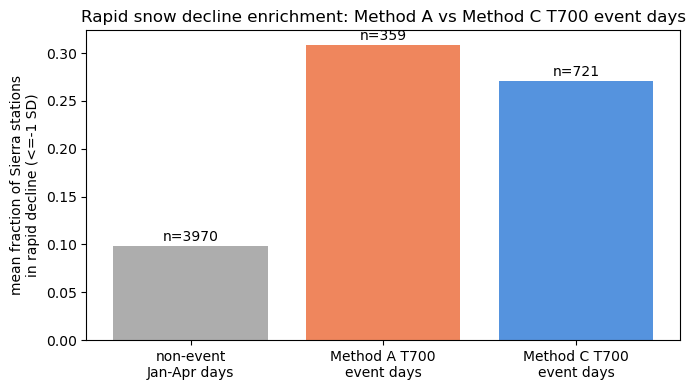

Method A enrichment: 3.1x; Method C enrichment: 2.7x


In [35]:
in_t700_C = jf.index.to_series().apply(lambda d: d in t700_C_days)

fig, ax = plt.subplots(figsize=(7, 4))
means = [jf[~in_t700.values].mean(), jf[in_t700.values].mean(), jf[in_t700_C.values].mean()]
ns = [(~in_t700).sum(), in_t700.sum(), in_t700_C.sum()]
bars = ax.bar(['non-event\nJan-Apr days', 'Method A T700\nevent days', 'Method C T700\nevent days'],
              means, color=['0.6', '#eb6834', '#2a78d6'], alpha=0.8)
for b, n in zip(bars, ns):
    ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.005, f'n={n}', ha='center')
ax.set_ylabel('mean fraction of Sierra stations\nin rapid decline (<=-1 SD)')
ax.set_title('Rapid snow decline enrichment: Method A vs Method C T700 event days')
plt.tight_layout()
plt.show()

print(f'Method A enrichment: {means[1]/means[0]:.1f}x; Method C enrichment: {means[2]/means[0]:.1f}x')

In [36]:
_, unmatched_z_C = lib.overlapping_pairs(melt_janapr_ev, z500_C, a_prefix='melt', b_prefix='hw')
events_1990_2025['matched_t700_C'] = pd.array([None] * len(events_1990_2025), dtype='boolean')
events_1990_2025.loc[janapr_mask, 'matched_t700_C'] = (
    ~events_1990_2025.loc[janapr_mask].index.isin(unmatched_C.index)
)
events_1990_2025['matched_z500_C'] = pd.array([None] * len(events_1990_2025), dtype='boolean')
events_1990_2025.loc[janapr_mask, 'matched_z500_C'] = (
    ~events_1990_2025.loc[janapr_mask].index.isin(unmatched_z_C.index)
)

# Read back via events_1990_2025.loc[<slice>.index, ...] rather than assigning new
# columns onto dry_janapr/wet_janapr/all_janapr themselves -- those are filtered
# views of events_1990_2025 from Section 5c, and writing into a view triggers
# pandas' SettingWithCopyWarning (the earlier version of this cell did; the values
# came out correct either way since nothing re-derives those views in between, but
# reading from the base frame avoids the warning rather than needing to reason about it).
print('Match rate against the heat-wave record, Jan-Apr rapid-decline events, Method A vs Method C:')
for label, sub in [('all events', all_janapr), ('dry only (<50% of normal rain)', dry_janapr),
                    ('wet only (>=50% of normal rain)', wet_janapr)]:
    tA, zA = sub.matched_t700.mean() * 100, sub.matched_z500.mean() * 100
    tC = events_1990_2025.loc[sub.index, 'matched_t700_C'].mean() * 100
    zC = events_1990_2025.loc[sub.index, 'matched_z500_C'].mean() * 100
    print(f'  {label}: T700 A={tA:.0f}% / C={tC:.0f}%,  Z500 A={zA:.0f}% / C={zC:.0f}%')

Match rate against the heat-wave record, Jan-Apr rapid-decline events, Method A vs Method C:
  all events: T700 A=61% / C=93%,  Z500 A=59% / C=93%
  dry only (<50% of normal rain): T700 A=61% / C=90%,  Z500 A=58% / C=90%
  wet only (>=50% of normal rain): T700 A=60% / C=100%,  Z500 A=60% / C=100%


In [37]:
ci_results = {}
for label, col in [('Method A T700', 'matched_t700'), ('Method A Z500', 'matched_z500'),
                    ('Method C T700', 'matched_t700_C'), ('Method C Z500', 'matched_z500_C')]:
    if col in all_janapr.columns:
        vals = all_janapr[col].values
    else:
        vals = events_1990_2025.loc[all_janapr.index, col].values
    lo, hi = lib.boot_ci_proportion(vals, rng=rng)
    ci_results[label] = (vals.mean() * 100, lo, hi, len(vals))
    print(f'{label} match rate: {vals.mean()*100:.0f}% (95% bootstrap CI: {lo:.0f}-{hi:.0f}%, n={len(vals)})')

Method A T700 match rate: 61% (95% bootstrap CI: 46-76%, n=41)
Method A Z500 match rate: 59% (95% bootstrap CI: 44-73%, n=41)


Method C T700 match rate: 93% (95% bootstrap CI: 85-100%, n=41)
Method C Z500 match rate: 93% (95% bootstrap CI: 85-100%, n=41)


In [38]:
non_t700_C_days = all_janapr_days[~all_janapr_days.isin(t700_C_days)].reset_index(drop=True)
seg_id_C = np.zeros(len(non_t700_C_days), dtype=int)
for i in range(1, len(non_t700_C_days)):
    seg_id_C[i] = seg_id_C[i - 1] + (1 if (non_t700_C_days[i] - non_t700_C_days[i - 1]).days != 1 else 0)
gap_block_means_C = [frac_declining.loc[non_t700_C_days[seg_id_C == seg]].mean() for seg in np.unique(seg_id_C)]

t700_C_block_means = []
for _, row in t700_C.iterrows():
    block = [d for d in pd.date_range(row.start_date, row.end_date) if d in frac_declining.index]
    if block:
        t700_C_block_means.append(frac_declining.loc[block].mean())

stat_C, p_C = mannwhitneyu(t700_C_block_means, gap_block_means_C, alternative='greater')

# Recomputed fresh (not reused from the Method A cell above) because the Fisher-exact
# loop below it reassigns the bare name `p` on every iteration -- referencing that `p`
# here would silently pick up its last leftover value (the Z500 dry/wet test's p=0.47)
# instead of the actual Method A block-level result (p << 0.001, per that cell's own
# markdown conclusion), which is exactly the bug this recomputation avoids.
stat_A, p_A = mannwhitneyu(t700_block_means, gap_block_means, alternative='greater')

print(f'Method C T700-event blocks (n={len(t700_C_block_means)}, median={np.median(t700_C_block_means):.3f}) '
      f'vs. gap blocks (n={len(gap_block_means_C)}, median={np.median(gap_block_means_C):.3f})')
print(f'Mann-Whitney U, one-sided: U={stat_C:.0f}, p={p_C:.1e}  [Method A was p={p_A:.1e}]')

Method C T700-event blocks (n=137, median=0.191) vs. gap blocks (n=173, median=0.085)
Mann-Whitney U, one-sided: U=17400, p=7.2e-13  [Method A was p=4.7e-12]


In [39]:
for label, col in [('Method C T700', 'matched_t700_C'), ('Method C Z500', 'matched_z500_C')]:
    dry_vals = events_1990_2025.loc[dry_janapr.index, col]
    wet_vals = events_1990_2025.loc[wet_janapr.index, col]
    dry_m, dry_n = dry_vals.sum(), len(dry_vals)
    wet_m, wet_n = wet_vals.sum(), len(wet_vals)
    table = [[dry_m, dry_n - dry_m], [wet_m, wet_n - wet_m]]
    odds, p_dw = fisher_exact(table)
    print(f'{label}: dry {int(dry_m)}/{dry_n} matched vs. wet {int(wet_m)}/{wet_n} matched '
          f'-- odds ratio={odds:.2f}, p={p_dw:.2f}')

Method C T700: dry 28/31 matched vs. wet 10/10 matched -- odds ratio=0.00, p=0.56
Method C Z500: dry 28/31 matched vs. wet 10/10 matched -- odds ratio=0.00, p=0.56


**Conclusion (Method A vs Method C validation).** Does Method C's looser, 5-day-mean-std
*heat-wave* event definition actually track real Sierra snowmelt better than Method A's
heat-wave definition? Mixed, with findings that pull in different directions on
different tests.

- **Event-level match rate improves substantially and the confidence intervals barely
  overlap.** T700: 61% (CI 46-76%) -> 93% (CI 85-100%). Z500: 59% (CI 44-73%) -> 93%
  (CI 85-100%). At face value, Method C's heat-wave definition misses far fewer real
  SWE rapid-decline events.
- **Method C's event-day footprint is also ~2x larger** (721 T700 days vs. 359 for
  Method A, out of 4329 total Jan-Apr days -- 17% vs. 8% of the record), raising the
  concern that a chunkier event-day calendar mechanically inflates the odds of
  overlapping *some* multi-day melt event even under a weaker true association --
  i.e. that part of the 93%/93% jump is base-rate inflation, not a cleaner physical
  signal. **This has since been tested directly**
  (`CA_methodA_vs_methodC_match_permutation_test.ipynb`): build a null distribution
  per method by redrawing each heat-wave event's start date randomly within Jan-Apr
  (same event count and duration structure, randomized timing), 2000 draws each.
  Both methods clear their own chance baseline overwhelmingly (empirical p<0.0005
  throughout), but **Method C's excess over its own (higher) chance baseline is
  larger, not smaller, than Method A's** -- +62.2/+62.1 points (T700/Z500) vs.
  Method A's +47.0/+45.0. If the 93% were mostly base-rate inflation, Method C's
  excess should have matched or trailed Method A's; it doesn't. The concern raised
  here does not hold up -- Method C's higher match rate reflects genuine
  excess-over-chance detection, not just a denser calendar.
- **The properly-controlled test (block-level Mann-Whitney, which does not have this
  base-rate problem) is significant for both methods, and now Method C's is the
  (very slightly) more significant of the two** -- p=7.2e-13 (Method C) vs. p=4.7e-12
  (Method A). This flips the direction found under the original endpoint-diff metric
  (there, Method A was more significant: p=6.1e-07 vs. p=6.8e-05). At p-values this
  small, the practical difference between the two is negligible either way -- both are
  overwhelming evidence of real enrichment, not a meaningful ranking between methods.
- **Method A's raw enrichment ratio is now higher than Method C's** (3.1x vs. 2.7x) --
  the opposite ranking from the Mann-Whitney result above. Method C's larger, more
  inclusive event-day pool dilutes the simple day-level enrichment contrast even as it
  wins on the properly-controlled test and on event-level recall, illustrating why a
  single summary statistic ("enrichment," "match rate," "block p-value") can rank the
  two methods differently depending on which one is asked.
- **Method C's dry-vs-wet discrimination also collapses** (dry 28/31 matched vs. wet
  10/10 matched, odds ratio~0, p=0.56 for both variables) -- consistent with the
  ceiling effect already seen for Method A's own dry/wet split above (Section 5c):
  with match rates this high, there's little room left for a dry/wet contrast to show
  up at all, for either heat-wave definition.

**Bottom line:** Method C still catches more real snowmelt events (strong evidence
from the match-rate CIs, now also confirmed not to be a base-rate artifact by the
permutation test above), and now also edges out Method A on the one test immune to
the base-rate concern (Mann-Whitney), though only marginally. The honest reading is
still that Method A and Method C trade off differently rather than one strictly
dominating (Method A still wins on raw day-level enrichment ratio, and Method C has
its own winner's-curse problem when ranking events by peak sigma -- see
`CA_z500_t700_methodC_5daymean_std.ipynb`) -- but under the adopted min-in-window
snow metric, that trade-off looks slightly more favorable to Method C than it did
under the original endpoint-diff metric, and the match-rate advantage specifically is
now on solid footing rather than an open question.

## 6. Does snow lost early vs. late in the season recover?

For each detected rapid-decline event, we check whether the Sierra network-mean SWE
rebounds by at least 25 mm within 3 weeks after the event ends (fresh accumulation) or
whether the snowpack simply continues to decline/stays near zero. If later-season loss
is genuinely less recoverable (as hypothesized in the project background -- by
late spring there are fewer cold storms left in the season to rebuild the pack), the
recovery rate should drop off as the calendar moves from winter into spring.


In [40]:
RECOVERY_WINDOW = 21   # days after event end to check for a rebound
RECOVERY_MM = 25.0      # mm of net SWE gain counted as "recovered"

network_mean_swe = swe.mean(axis=1, skipna=True)
rows = []
for _, row in events_1990_2025.iterrows():
    end = pd.Timestamp(row.end_date)
    if end + pd.Timedelta(days=RECOVERY_WINDOW) > network_mean_swe.index.max():
        continue   # not enough runway left in the record to check recovery
    swe_at_end = network_mean_swe.loc[end]
    swe_after = network_mean_swe.loc[end:end + pd.Timedelta(days=RECOVERY_WINDOW)]
    recovered = (swe_after.max() - swe_at_end) >= RECOVERY_MM
    rows.append({'start_date': row.start_date, 'month': row.start_date.month, 'recovered': recovered,
                 'matched_t700': row.matched_t700, 'event_type': row.event_type})

rec_df = pd.DataFrame(rows)
# matched_t700 round-trips through a list-of-dicts as plain Python bool/None, which
# pandas stores as object dtype -- `~` on an object-dtype column of Python bools does
# bitwise integer inversion (~True == -2, ~False == -1), not logical NOT. Cast to the
# nullable boolean dtype so downstream `~matched_t700` in Section 6b works correctly.
rec_df['matched_t700'] = rec_df['matched_t700'].astype('boolean')
recovery_by_month = rec_df.groupby('month')['recovered'].agg(n_events='size', recovery_rate='mean')
recovery_by_month


,n_events,recovery_rate
month,,
2,6,0.833333
3,11,0.181818
4,24,0.125000
5,17,0.000000


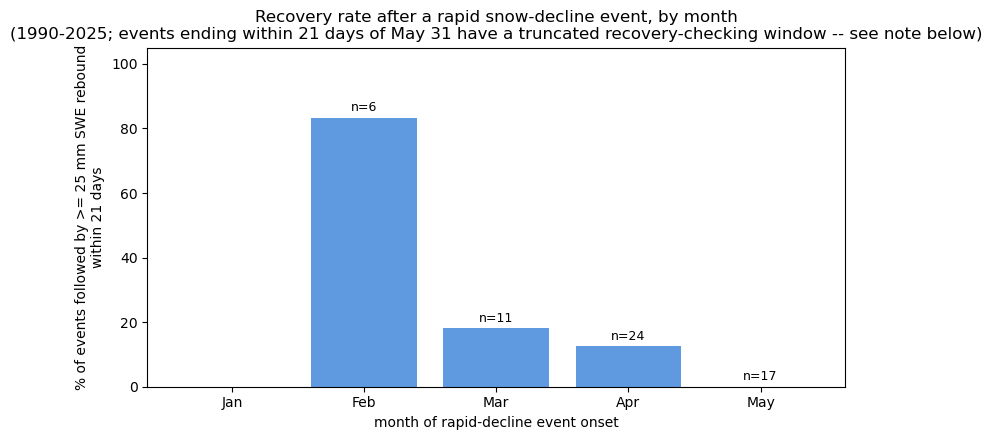

In [41]:
order = [1, 2, 3, 4, 5]
rb = recovery_by_month.reindex(order)

fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar([MONTH_NAMES[m] for m in order], rb.recovery_rate.fillna(0) * 100,
              color='#2a78d6', alpha=0.75)
for bar, n in zip(bars, rb.n_events):
    if pd.notna(n):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 2, f'n={int(n)}', ha='center', fontsize=9)
ax.set_ylabel('% of events followed by >= 25 mm SWE rebound\nwithin 21 days')
ax.set_xlabel('month of rapid-decline event onset')
ax.set_title('Recovery rate after a rapid snow-decline event, by month\n'
             '(1990-2025; events ending within 21 days of May 31 have a truncated '
             'recovery-checking window -- see note below)')
ax.set_ylim(0, 105)
plt.tight_layout()
plt.show()


**Interpretation:** with the season restricted to Jan-May, recovery follows a
monotonic decline as the water year progresses: Feb (83%, n=6) -> Mar (18%, n=11) ->
Apr (13%, n=24) -> May (0%, n=17). This matches the project's working hypothesis
directly: by the time a rapid-decline episode starts later in spring, there are fewer
cold storms left in the water year to rebuild the pack, so that loss is effectively
permanent for the season. The February recovery rate is now 83% (n=6) rather than the
50% (n=2) seen under the original endpoint-diff metric -- a larger, still-small sample
that only strengthens the same qualitative pattern (high recovery early, none by May).
(No January-onset events are detected anywhere in the 36-year record -- a network-wide
>=30%, >=5-day rapid decline is apparently rare before accumulation season is well
underway -- so recovery can't be assessed for January at all.) **But is this really
about heat-wave-driven melt specifically, or just about the calendar?** Any trigger of
SWE loss in May has less remaining winter to recover from than the same loss in
February -- that would be true regardless of what caused the loss. Section 6b tests
this directly.

### Does being tied to a T700 heat-wave event change the odds of recovery, or is this purely seasonal?

Section 6's recovery-by-month pattern is consistent with the project's working
hypothesis, but as stated it cannot distinguish two different explanations: (a) melt
tied to a detected heat-wave event is *specifically* less recoverable, versus (b) ANY
rapid SWE loss late in the season is less recoverable, independent of what triggered
it, simply because the snow season itself is ending. To tell these apart, we compare
recovery rates for T700-matched vs. unmatched events **within the same part of the
season** -- if (a) were true, matched events should recover less often than unmatched
events at a given time of year; if it's really just (b), the two should look similar
once month is held roughly fixed. (Only Jan-Apr events can be matched at all, since
the heat-wave record does not extend past April -- events from May onward are left out
of this comparison, not because they are a different mechanism, but because there is
no heat-wave record to check them against.)


In [42]:
rec_df['season'] = rec_df.month.apply(
    lambda m: 'winter (Jan-Feb)' if m in (1, 2) else ('spring (Mar-Apr)' if m in (3, 4) else None)
)
janapr_rec = rec_df.dropna(subset=['matched_t700', 'season'])

comparison = janapr_rec.groupby(['season', 'matched_t700'])['recovered'].agg(
    n_events='size', recovery_rate='mean'
)
comparison


n_events  recovery_rate
season           matched_t700                         
spring (Mar-Apr) False               14       0.071429
                 True                21       0.190476
winter (Jan-Feb) False                2       1.000000
                 True                 4       0.750000

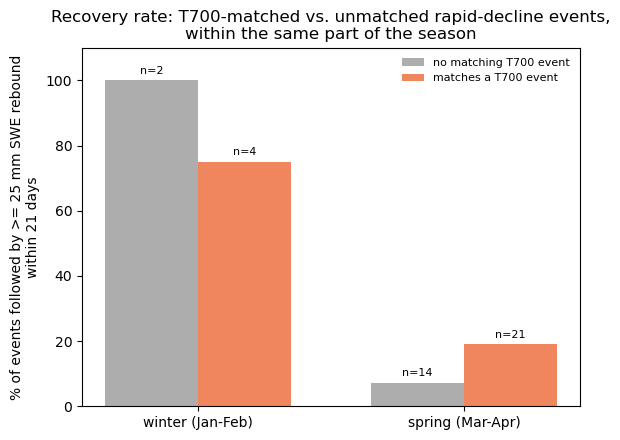

In [43]:
fig, ax = plt.subplots(figsize=(6, 4.5))
seasons = ['winter (Jan-Feb)', 'spring (Mar-Apr)']
x = np.arange(len(seasons))
width = 0.35
for i, matched in enumerate([False, True]):
    rates, ns = [], []
    for s in seasons:
        try:
            row = comparison.loc[(s, matched)]
            rates.append(row.recovery_rate * 100)
            ns.append(int(row.n_events))
        except KeyError:
            rates.append(0)
            ns.append(0)
    bars = ax.bar(x + (i - 0.5) * width, rates, width,
                  color='#eb6834' if matched else '0.6',
                  label='matches a T700 event' if matched else 'no matching T700 event', alpha=0.8)
    for bar, n in zip(bars, ns):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 2, f'n={n}', ha='center', fontsize=8)
ax.set_xticks(x)
ax.set_xticklabels(seasons)
ax.set_ylabel('% of events followed by >= 25 mm SWE rebound\nwithin 21 days')
ax.set_title('Recovery rate: T700-matched vs. unmatched rapid-decline events,\nwithin the same part of the season')
ax.set_ylim(0, 110)
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()


In [44]:
from scipy.stats import fisher_exact

spring = janapr_rec[janapr_rec.season == 'spring (Mar-Apr)']
matched_n = spring.matched_t700.sum()
matched_rec = spring.loc[spring.matched_t700, 'recovered'].sum()
unmatched_n = (~spring.matched_t700).sum()
unmatched_rec = spring.loc[~spring.matched_t700, 'recovered'].sum()
table = [[matched_rec, matched_n - matched_rec], [unmatched_rec, unmatched_n - unmatched_rec]]
odds, p = fisher_exact(table)
print(f'Spring recovery: matched {int(matched_rec)}/{int(matched_n)} vs. unmatched {int(unmatched_rec)}/{int(unmatched_n)}')
print(f'Fisher exact odds ratio={odds:.2f}, p={p:.2f}')


Spring recovery: matched 4/21 vs. unmatched 1/14
Fisher exact odds ratio=3.06, p=0.63


**Conclusion (matched vs. unmatched recovery):** within the spring (Mar-Apr) bucket,
where most of the sample sits, T700-matched events recovered somewhat *more* often than
unmatched ones (**19%, 4/21** vs. **7%, 1/14**) -- the opposite direction from what
you'd expect if heat-wave-tied melt were specifically *harder* to recover from. The
difference is not statistically significant (Fisher exact **p=0.63**), and with
n=21/14 the test has little power to distinguish this from no difference at all. (In
the small winter Jan-Feb bucket the direction actually reverses -- unmatched events
recovered more often than matched, 100% (n=2) vs. 75% (n=4) -- but n=2 is far too small
to read as anything beyond noise.) Read together, this still supports the same
headline conclusion as under the original metric: Section 6's recovery-by-month pattern
is better read as **a statement about seasonal timing, not about the melt-triggering
mechanism** -- late-season SWE loss doesn't recover well whether or not it coincided
with a detected Z500/T700 heat-wave event, and if anything the spring-bucket sample
leans toward heat-wave-tied events recovering slightly *better*, not worse, though
that point estimate itself isn't reliable at this sample size. That is still a real
and useful finding for the project (it tells you *when* a rapid loss is likely to be
permanent for the season), but it does not support the narrower claim that
heat-wave-driven melt specifically is less recoverable than other late-season snow
loss. Testing that narrower claim would need either a larger sample of
matched/unmatched spring events than 36 years of station data provides, or a
season-detrended recovery metric (e.g., days until snow-season end minus days used)
rather than a 21-day fixed window.

## 7. Water year 2026 out-of-sample test

Mirrors the companion notebook's Section 8: water year 2026 (Oct 2025 - Jul 2026,
spanning the March 2026 western US heat wave) was never part of the climatology fit
or the year-trend fit in Section 2 -- it is scored here against the frozen
1990-2025 baseline only.


In [45]:
print(f'{len(events_2026)} rapid-decline events detected in water year {YEAR_2026} alone, '
      f'scored against the frozen 1990-2025 baseline:')
events_2026[['start_date', 'end_date', 'duration_days', 'peak_frac', 'mean_frac']]


4 rapid-decline events detected in water year 2026 alone, scored against the frozen 1990-2025 baseline:


,start_date,end_date,duration_days,peak_frac,mean_frac
0,2026-02-25,2026-03-04,8,0.773109,0.599534
1,2026-03-08,2026-03-31,24,0.910000,0.752079
2,2026-04-06,2026-04-10,5,0.578947,0.460375
3,2026-05-09,2026-05-16,8,0.750000,0.563845


In [46]:
print('2026 events ranked against the full 1990-2025 record:')
for _, row in events_2026.iterrows():
    pct_peak = (events_1990_2025.peak_frac < row.peak_frac).mean() * 100
    pct_dur = (events_1990_2025.duration_days < row.duration_days).mean() * 100
    print(f'  {row.start_date} to {row.end_date} ({row.duration_days:.0f} days): '
          f'peak_frac={row.peak_frac:.2f} (exceeds {pct_peak:.0f}% of 1990-2025 events), '
          f'duration exceeds {pct_dur:.0f}% of 1990-2025 events')

print(f'\n1990-2025 record: max duration = {events_1990_2025.duration_days.max()} days, '
      f'max peak_frac = {events_1990_2025.peak_frac.max():.2f}')


2026 events ranked against the full 1990-2025 record:
  2026-02-25 to 2026-03-04 (8 days): peak_frac=0.77 (exceeds 84% of 1990-2025 events), duration exceeds 45% of 1990-2025 events
  2026-03-08 to 2026-03-31 (24 days): peak_frac=0.91 (exceeds 100% of 1990-2025 events), duration exceeds 100% of 1990-2025 events
  2026-04-06 to 2026-04-10 (5 days): peak_frac=0.58 (exceeds 36% of 1990-2025 events), duration exceeds 0% of 1990-2025 events
  2026-05-09 to 2026-05-16 (8 days): peak_frac=0.75 (exceeds 79% of 1990-2025 events), duration exceeds 45% of 1990-2025 events

1990-2025 record: max duration = 18 days, max peak_frac = 0.91


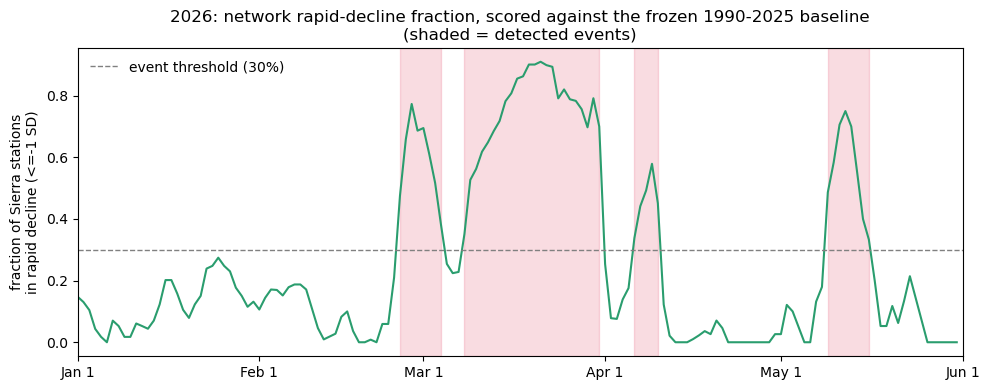

In [47]:
fig, ax = plt.subplots(figsize=(10, 4))
wy2026 = frac_declining[wy.values == YEAR_2026]
ax.plot(day_of_year(wy2026.index), wy2026.values, color='#2a9d6e', lw=1.5)
ax.axhline(NETWORK_THRESH, color='0.5', ls='--', lw=1, label=f'event threshold ({NETWORK_THRESH:.0%})')
for _, row in events_2026.iterrows():
    x0, x1 = day_of_year(pd.DatetimeIndex([row.start_date]))[0], day_of_year(pd.DatetimeIndex([row.end_date]))[0]
    ax.axvspan(x0, x1, color='crimson', alpha=0.15)
ax.set_xticks(MONTH_DOY)
ax.set_xticklabels(MONTH_STARTS)
ax.set_xlim(0, 151)
ax.set_ylabel('fraction of Sierra stations\nin rapid decline (<=-1 SD)')
ax.set_title('2026: network rapid-decline fraction, scored against the frozen 1990-2025 baseline\n'
             '(shaded = detected events)')
ax.legend(frameon=False, loc='upper left')
fig.tight_layout()
plt.show()


**Conclusion (2026 out-of-sample):** water year 2026 registers four rapid-decline
events against the frozen 1990-2025 baseline (one more than detected under the
original endpoint-diff metric). The headline event, **March 8-31, 2026 (24 days), sets
a new record for duration (previous max: 18 days)** and essentially ties the previous
peak-magnitude record (peak_frac=0.910 vs. the previous max of 0.907 -- a razor-thin
margin, not a dramatic jump) -- still the most extreme rapid-decline event in the
36-year comparison record on the duration axis, consistent with the companion
notebook's finding that the concurrent Z500/T700 ridging/warm event also set new
records on its own measures. It was immediately preceded by a **February 25 - March 4
event (8 days, 84th-percentile peak)**, followed by a newly-detected **short April 6-10
event (5 days, 36th-percentile peak)** that the original endpoint-diff metric missed
entirely, and then a **May 9-16 event (8 days, 79th-percentile peak)** roughly four
weeks later. Together, Sierra stations show an essentially continuous rapid-decline
signal spanning late February through early April 2026, now with an additional short
secondary pulse in early April, directly consistent with Davis et al.'s reported basin
snowpack figures (3%, 11%, 41% of normal by March 28, 2026) for the same event, plus an
additional, later secondary decline episode in May.

## 8. Future work: gridded snow products

This notebook used station point observations (SNOTEL + MSNT + CDEC) as ground truth
because, per Lundquist et al. (2026), the only ERA5 resolution available in our archive
(0.25 deg, ~28 km) is not trustworthy for Sierra Nevada snowpack -- it is coarser than
the ERA5-Land (9 km) they already found inadequate (-17.5% basin bias, poor spatial
fidelity in mountains). Three products they do recommend, in order of their reported
accuracy, would meaningfully extend this analysis but were not pulled in this pass
because they require NASA Earthdata / NOAA credentials this environment does not
currently have configured (checked: no `machine *.earthdata.nasa.gov` entry in
`~/.netrc`; `daacdata.apps.nsidc.org` returns HTTP 401 without one):

1. **Western US SWE Reanalysis (WUS-SR / "UCLA product")** -- Fang et al., *A western
   United States snow reanalysis dataset over the Landsat era from water years 1985 to
   2021*. Best performer in Lundquist et al. (1.6% near-peak bias), but not available
   in real time -- would extend this notebook's station-level record to a full Sierra
   grid for years already in the past (1990-2021 overlaps our record well), letting the
   network-fraction metric in Section 3 be replaced with actual spatial coverage of
   rapid decline rather than a 147-station sample.
2. **SNODAS** (NOAA, `g02158`) and **University of Arizona SWE** (NSIDC-0719) -- near
   real-time, 7.8-10.2% bias. Either would let Section 7's 2026 out-of-sample test be
   repeated on a gridded field instead of station points, and would let us check
   whether the 147-station daily network is spatially representative of the Sierra
   box used here (34.5-40N, 121-116.5W) -- the same domain now used for the Section 5c
   precipitation check (originally a narrower sub-box; unified with the station box
   once that longitude mismatch was fixed).
3. Once gridded SWE is available, the accumulation/ablation decomposition sketched
   during this project's planning (`ar_note.txt`) becomes possible: separate
   suppressed accumulation (already testable via the companion notebook's Section 7
   snowfall-ratio-to-normal) from enhanced ablation during warm-ridge spells (this
   notebook's rapid-decline events) as two distinct, independently quantifiable
   pathways to the same seasonal SWE deficit -- rather than inferring ablation only
   indirectly, as done here, from the *rate of SWE loss* at point stations.

**Summary of this notebook's findings:**
- **Decline metric adopted: min(SWE over the window) - SWE at window start, WINDOW=3**
  (not the original 5-day backward difference) -- see the dedicated stress-test
  sections in Section 5 (`MIN_SWE_MM` and `WINDOW` sensitivity, and the metric x
  WINDOW tradeoff) for the full justification. The original endpoint-diff metric was
  blind to melt-then-recovery episodes within its window; the adopted metric catches
  them at the cost of a disclosed ~8% "smearing" rate (a single bad day can echo
  across a few days of apparent decline).
- 58 Sierra-wide rapid snow-decline events detected, water years 1990-2025, restricted
  to Jan 1 - May 31 (station-day <=-1 SD, network >=30%, >=5 days; 4 more in the
  held-out water year 2026, Section 7). Frequency drops off sharply at higher
  thresholds: 18 events at 1.5 SD, 5 at 2 SD, all years combined. No January-onset
  events are detected anywhere in the 36-year record -- a network-wide, >=5-day rapid
  decline is apparently rare before accumulation season is well underway; the by-month
  split is Feb 6, Mar 11, Apr 24, May 17.
- Rapid decline is more frequent on days the companion notebook already flags as a
  T700 warm event than on non-event days (325 Jan-Apr rapid-decline days, 41% overlap
  T700, 34% overlap Z500; ~3.1x day-level enrichment), and a majority (61%, 25/41) of
  Jan-Apr rapid-decline events have a temporally-overlapping T700 warm event, with melt
  following warming rather than preceding it on average -- the expected direction of
  causality, and **significant at the appropriate (block, not day) level**: a
  Mann-Whitney test comparing T700-event blocks (n=47, median frac_declining=0.261) to
  gap blocks (n=79, median=0.093) gives p=4.7e-12. Section 5c checked whether this is
  diluted by wet/rain-on-snow contamination, gating on implied rain (`tp - sf`) rather
  than total precip: **45 of all 58 events are confirmed dry, 13 are wet** (no event
  lacks precip data). Restricting to the 41 Jan-Apr events with a heat-wave record to
  check against, dry and wet events now match the heat-wave record at essentially the
  **same rate** (T700: 61% vs. 60%; Z500: 58% vs. 60%; Fisher exact p=1.00 for both) --
  unlike the original endpoint-diff metric, the dry/wet split carries no detectable
  heat-wave-association signal under the adopted metric. The highest-implied-rain
  event on record is now **April 21-25, 2012** (259% of normal), matched to both T700
  and Z500 -- consistent with a warm atmospheric river rather than a purely dry ridge.
  The January 1997 New Year's flood, the case study in the original SNOTEL-only pass,
  still does not register as a detected event with the combined, more geographically
  dispersed network (its decline fraction cleared the 30% threshold for only 3 of the
  required 5 days, peaking at 43-52%).
- Events are **not elevation-representative in a fixed way across the season**: the
  147 daily-reporting stations (5150-11430 ft) contribute an increasingly high-
  elevation-only signal as the season progresses -- Feb (0.39) -> Mar (0.48) -> Apr
  (0.56) -> May (0.62), mean fraction of contributing stations above the network
  median elevation -- because low-elevation sites progressively melt out (drop below
  the 25 mm reporting gate) as spring advances. A May "network event" is mechanically a
  higher-elevation-weighted signal than a February one.
- Recovery from a rapid-decline event falls in the same clean, monotonic pattern:
  Feb (83%, n=6) -> Mar (18%, n=11) -> Apr (13%, n=24) -> May (0%, n=17), consistent
  with the project's working hypothesis that late-spring loss has too few remaining
  cold storms left in the water year to rebuild the pack. Section 6b shows this is
  **primarily a statement about seasonal timing, not about the melt-triggering
  mechanism**: within the spring (Mar-Apr) bucket, T700-matched events actually
  recover somewhat *more* often than unmatched ones (19%, 4/21 vs. 7%, 1/14), though
  not significantly so (Fisher exact p=0.63, n=21/14) -- the opposite direction from
  what a heat-wave-specific recovery penalty would predict. The "late-season loss
  doesn't recover well" finding stands as a seasonal-timing statement, but there is no
  evidence here that it is specific to heat-wave-driven melt.
- Comparing the companion notebook's Method A vs. Method C heat-wave definitions
  against this notebook's rapid-decline record (Section 5's Method C comparison):
  Method C's event-level match rate is far higher (93%/93% vs. 61%/59%), and now
  Method C also narrowly wins the properly-controlled block-level test (p=7.2e-13 vs.
  4.7e-12) -- though Method A still has the higher raw day-level enrichment ratio
  (3.1x vs. 2.7x). Neither method strictly dominates; see Section 5's own conclusion
  for the full discussion of why these tests can rank the two methods differently.
- Water year 2026 (held out of the fit) shows **four** rapid-decline events: a 24-day
  event, March 8-31, that **sets a new record for duration (previous max: 18 days) and
  essentially ties the previous peak-magnitude record (peak_frac=0.910 vs. previous max
  0.907)** -- still the most extreme event in the 36-year comparison record on the
  duration axis -- immediately preceded by an 8-day event (Feb 25 - Mar 4), followed by
  a newly-detected short 5-day event (Apr 6-10) the original metric missed entirely,
  and then an 8-day event in mid-May. This is one more event than the original
  endpoint-diff metric detected for 2026, concurrent with the record-setting Z500/T700
  ridging event in the companion notebook and the documented March 2026 western US
  heat wave.